# Echo — Groupe 6

Faut-il généraliser les notifications agressives chez Echo ?

## Inspection des données

Les contrôles ci-dessous portent sur les CSV bruts. Aucune correction n'est appliquée.

In [1]:
from pathlib import Path
import pandas as pd

# Le notebook peut être ouvert depuis la racine du dépôt.
data_dir = Path("data")
if not data_dir.is_dir():
    raise FileNotFoundError("Ouvrir le notebook depuis le dossier GrowthModel.")

users_raw = pd.read_csv(data_dir / "users.csv", dtype={"user_id": "string"})
activity_raw = pd.read_csv(data_dir / "weekly_activity.csv", dtype={"user_id": "string"})
spend_raw = pd.read_csv(data_dir / "marketing_spend.csv")
tables = {"users": users_raw, "weekly_activity": activity_raw, "marketing_spend": spend_raw}

for name, table in tables.items():
    print(f"{name} : {len(table):,} lignes, {len(table.columns)} colonnes")
    print(table.dtypes.to_string())
    print()


users : 20,909 lignes, 7 colonnes
user_id                 string[python]
signup_date                     object
acquisition_channel             object
platform                        object
age_bucket                      object
push_variant                    object
shows_followed_week1             int64

weekly_activity : 334,399 lignes, 6 colonnes
user_id                        string[python]
week_start                             object
sessions                                int64
listening_minutes                     float64
ad_impressions                          int64
push_notifications_received             int64

marketing_spend : 17 lignes, 3 colonnes
month         object
channel       object
spend_eur    float64



### Valeurs manquantes et doublons

In [2]:
keys = {"users": ["user_id"], "weekly_activity": ["user_id", "week_start"], "marketing_spend": ["month", "channel"]}
audit_rows = []
for name, table in tables.items():
    distinct_rows = table.drop_duplicates()
    audit_rows.append({
        "table": name,
        "lignes": len(table),
        "copies_exactes": int(table.duplicated().sum()),
        "cles_repetees": int(table.duplicated(keys[name]).sum()),
        "lignes_en_conflit_apres_dedoublonnage": int(distinct_rows.duplicated(keys[name], keep=False).sum()),
    })
    print(f"Valeurs manquantes — {name}")
    print(table.isna().sum().to_string())
    print()
print(pd.DataFrame(audit_rows).to_string(index=False))


Valeurs manquantes — users
user_id                   0
signup_date               0
acquisition_channel       0
platform                  0
age_bucket              660
push_variant              0
shows_followed_week1      0

Valeurs manquantes — weekly_activity
user_id                        0
week_start                     0
sessions                       0
listening_minutes              0
ad_impressions                 0
push_notifications_received    0

Valeurs manquantes — marketing_spend
month        0
channel      0
spend_eur    0

          table  lignes  copies_exactes  cles_repetees  lignes_en_conflit_apres_dedoublonnage
          users   20909             124            124                                      0
weekly_activity  334399            1663           1663                                      0
marketing_spend      17               0              0                                      0


### Dates et catégories

Les dates avec `/` sont lues au format jour/mois/année. Les jours supérieurs à 12 permettent de vérifier cette convention. Les colonnes de contrôle ne remplacent pas les données brutes.

In [3]:
slash_dates = users_raw["signup_date"].str.contains("/", regex=False)
signup_dates = pd.to_datetime(users_raw["signup_date"], format="%Y-%m-%d", errors="coerce")
signup_dates.loc[slash_dates] = pd.to_datetime(users_raw.loc[slash_dates, "signup_date"], format="%d/%m/%Y", errors="coerce")
week_dates = pd.to_datetime(activity_raw["week_start"], format="%Y-%m-%d", errors="coerce")
month_dates = pd.to_datetime(spend_raw["month"], format="%Y-%m-%d", errors="coerce")

print("Dates d'inscription avec / :", int(slash_dates.sum()))
print("Dont jour supérieur à 12 :", int((users_raw.loc[slash_dates, "signup_date"].str[:2].astype(int) > 12).sum()))
print("Dates invalides (inscription, semaine, dépense) :", int(signup_dates.isna().sum()), int(week_dates.isna().sum()), int(month_dates.isna().sum()))
print("Inscriptions :", signup_dates.min().date(), "à", signup_dates.max().date())
print("Activité :", week_dates.min().date(), "à", week_dates.max().date())
print("Semaines ne commençant pas un lundi :", int((week_dates.dt.dayofweek != 0).sum()))
print("Dépenses non datées du premier du mois :", int((month_dates.dt.day != 1).sum()))
for column in ["acquisition_channel", "platform", "age_bucket", "push_variant"]:
    print(f"\n{column}")
    print(users_raw[column].value_counts(dropna=False).to_string())


Dates d'inscription avec / : 314
Dont jour supérieur à 12 : 193
Dates invalides (inscription, semaine, dépense) : 0 0 0
Inscriptions : 2025-01-01 à 2026-06-30
Activité : 2024-12-30 à 2026-06-29
Semaines ne commençant pas un lundi : 0
Dépenses non datées du premier du mois : 0

acquisition_channel
acquisition_channel
paid_social            8950
organic_store          7722
podcast_cross_promo    4237

platform
platform
Android    10496
iOS        10413

age_bucket
age_bucket
25-34    7043
18-24    5964
35-44    4143
45+      3099
NaN       660

push_variant
push_variant
standard           18181
control             1276
aggressive_push     1240
Control              100
AGGRESSIVE_PUSH       58
aggressive            54


### Valeurs numériques

In [4]:
print(activity_raw.select_dtypes("number").describe(percentiles=[0.5, 0.99]).round(2).to_string())
print("\nDurées négatives :", int((activity_raw["listening_minutes"] < 0).sum()))
# Une semaine entière représente 10 080 minutes.
print("Durées supérieures à une semaine :", int((activity_raw["listening_minutes"] > 7 * 24 * 60).sum()))
print("Durées exactement égales à une semaine :", int(activity_raw["listening_minutes"].eq(7 * 24 * 60).sum()))
print("Émissions suivies en semaine 1 :")
print(users_raw["shows_followed_week1"].describe().to_string())
for name, table, columns in [
    ("users", users_raw, ["shows_followed_week1"]),
    ("weekly_activity", activity_raw, ["sessions", "ad_impressions", "push_notifications_received"]),
    ("marketing_spend", spend_raw, ["spend_eur"]),
]:
    print(name, "— valeurs négatives :", (table[columns] < 0).sum().to_dict())


        sessions  listening_minutes  ad_impressions  push_notifications_received
count  334399.00          334399.00       334399.00                    334399.00
mean        3.51             114.53           11.56                         5.26
std         1.84            1737.45            6.88                         6.23
min         1.00              -1.00            1.00                         0.00
50%         3.00              70.10           10.00                         4.00
99%         9.00             264.30           32.00                        36.00
max        21.00           99999.00           82.00                        58.00

Durées négatives : 96
Durées supérieures à une semaine : 100
Durées exactement égales à une semaine : 105
Émissions suivies en semaine 1 :
count    20909.000000
mean         2.211010
std          1.551813
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         12.000000
users — valeurs négatives : {'shows_

### Cohérence entre les fichiers et couverture

Une semaine sans ligne signifie qu'aucune activité n'est enregistrée. Elle ne prouve pas un départ définitif. La première et la dernière semaine peuvent être partielles.

In [5]:
print("Utilisateurs de l'activité absents de users :", len(set(activity_raw["user_id"]) - set(users_raw["user_id"])))
print("Utilisateurs sans activité :", len(set(users_raw["user_id"]) - set(activity_raw["user_id"])))

# Dédupliquer seulement la table de correspondance pour éviter une jointure plusieurs-à-plusieurs.
signup_lookup = pd.DataFrame({"user_id": users_raw["user_id"], "signup_date": signup_dates}).drop_duplicates()
joined = activity_raw[["user_id", "week_start"]].merge(signup_lookup, on="user_id", how="left", validate="many_to_one")
signup_monday = joined["signup_date"] - pd.to_timedelta(joined["signup_date"].dt.dayofweek, unit="D")
print("Activités antérieures à la semaine d'inscription :", int((pd.to_datetime(joined["week_start"]) < signup_monday).sum()))
print("Activités après l'extraction du 30/06/2026 :", int((week_dates > pd.Timestamp("2026-06-30")).sum()))

all_months = pd.date_range("2025-01-01", "2026-06-01", freq="MS")
for channel in spend_raw["channel"].unique():
    recorded_months = month_dates[spend_raw["channel"] == channel]
    print("Mois de dépenses absents pour", channel, ":", all_months.difference(recorded_months).strftime("%Y-%m").tolist())
print("Canaux sans dépenses renseignées :", sorted(set(users_raw["acquisition_channel"]) - set(spend_raw["channel"])))

test_users = pd.DataFrame({"signup_date": signup_dates, "push_variant": users_raw["push_variant"]}).loc[users_raw["push_variant"] != "standard"]
outside_test = ~test_users["signup_date"].between("2026-01-15", "2026-03-15")
print("Lignes de participants inscrits hors de la période du test :", int(outside_test.sum()))


Utilisateurs de l'activité absents de users : 0
Utilisateurs sans activité : 0
Activités antérieures à la semaine d'inscription : 0
Activités après l'extraction du 30/06/2026 : 0
Mois de dépenses absents pour paid_social : ['2025-05']
Canaux sans dépenses renseignées : ['organic_store', 'podcast_cross_promo']
Lignes de participants inscrits hors de la période du test : 0


### Bilan

- 124 copies exactes dans `users` et 1 663 dans `weekly_activity`, sans conflit de valeurs sur les clés.
- 314 dates d'inscription au format jour/mois/année.
- Variantes à harmoniser : `Control`, `AGGRESSIVE_PUSH` et `aggressive`.
- 660 âges absents dans le brut.
- 96 durées négatives et 100 durées de 99 999 minutes dans le brut.
- Dépense `paid_social` de mai 2025 absente. Aucun coût renseigné pour les autres canaux.
- Aucun indicateur fiable ne permet d'identifier des comptes internes ou de test. Aucun compte n'est exclu sur une simple suspicion.

Les règles validées sont appliquées dans la section suivante. Les effectifs changeront après retrait des copies exactes.

## Nettoyage

Choix validés : conserver les utilisateurs sans âge dans la catégorie `inconnu`, remplacer uniquement les durées impossibles par une valeur manquante, et estimer la dépense de mai 2025 entre avril et juin. Les CSV bruts restent intacts. Le journal compte les lignes affectées à chaque étape, dans l'ordre d'exécution.

In [6]:
users = users_raw.copy()
activity = activity_raw.copy()
spend = spend_raw.copy()
cleaning_log = []

def log_rule(table, rule, reason, affected, before, after):
    cleaning_log.append({
        "ordre": len(cleaning_log) + 1,
        "table": table,
        "regle": rule,
        "justification": reason,
        "lignes_affectees": int(affected),
        "lignes_avant": int(before),
        "lignes_apres": int(after),
    })

for name, table in [("users", users), ("weekly_activity", activity)]:
    before = len(table)
    table.drop_duplicates(inplace=True)
    log_rule(name, "Supprimer les copies exactes", "Une observation ne doit être comptée qu'une fois. Aucun conflit sur les clés après dédoublonnage.", before - len(table), before, len(table))

slash = users["signup_date"].str.contains("/", regex=False)
parsed_signup = pd.to_datetime(users["signup_date"], format="%Y-%m-%d", errors="coerce")
parsed_signup.loc[slash] = pd.to_datetime(users.loc[slash, "signup_date"], format="%d/%m/%Y", errors="raise")
assert parsed_signup.notna().all(), "Date d'inscription non reconnue"
users["signup_date"] = parsed_signup
activity["week_start"] = pd.to_datetime(activity["week_start"], format="%Y-%m-%d", errors="raise")
spend["month"] = pd.to_datetime(spend["month"], format="%Y-%m-%d", errors="raise")
log_rule("users", "Uniformiser les dates d'inscription en AAAA-MM-JJ", "Les dates avec / suivent le format jour/mois/année, confirmé par les jours supérieurs à 12.", slash.sum(), len(users), len(users))

variant_mapping = {"Control": "control", "AGGRESSIVE_PUSH": "aggressive_push", "aggressive": "aggressive_push"}
changed_variants = users["push_variant"].isin(variant_mapping)
users["push_variant"] = users["push_variant"].replace(variant_mapping)
log_rule("users", "Harmoniser les libellés des variantes push", "Les trois libellés correspondent aux variantes décrites dans le data pack.", changed_variants.sum(), len(users), len(users))

missing_age = users["age_bucket"].isna()
users["age_bucket"] = users["age_bucket"].fillna("inconnu")
log_rule("users", "Remplacer l'âge absent par inconnu", "Conserver les utilisateurs et ne pas inventer leur âge. Les comparaisons par âge présenteront inconnu séparément.", missing_age.sum(), len(users), len(users))
print("Utilisateurs après nettoyage :", len(users))
print(users["push_variant"].value_counts().to_string())


Utilisateurs après nettoyage : 20785
push_variant
standard           18076
control             1366
aggressive_push     1343


### Durées d'écoute

Une durée négative ou supérieure à 10 080 minutes est impossible. Une durée exactement égale à 10 080 minutes représente sept jours sans pause : on la considère comme suspecte et on l'écarte aussi des calculs d'écoute, sans affirmer qu'elle est nécessairement erronée.

On conserve les autres mesures de la ligne. `listening_minutes_invalid` marque les durées impossibles ; `listening_minutes_suspect` marque celles exactement égales à une semaine. Les deux sont remplacées par une valeur manquante, jamais par zéro. Les valeurs d'origine restent dans les CSV bruts.

In [7]:
negative_minutes = activity["listening_minutes"] < 0
over_week_minutes = activity["listening_minutes"] > 7 * 24 * 60
continuous_week_minutes = activity["listening_minutes"].eq(7 * 24 * 60)
activity["listening_minutes_invalid"] = negative_minutes | over_week_minutes
activity["listening_minutes_suspect"] = continuous_week_minutes
activity.loc[activity["listening_minutes_invalid"] | activity["listening_minutes_suspect"], "listening_minutes"] = float("nan")

log_rule("weekly_activity", "Mettre les durées négatives à manquant", "Garder les sessions, impressions et notifications de la ligne.", negative_minutes.sum(), len(activity), len(activity))
log_rule("weekly_activity", "Mettre les durées supérieures à 10 080 minutes à manquant", "La durée dépasse une semaine entière. Aucun plafonnement ni remplacement par zéro.", over_week_minutes.sum(), len(activity), len(activity))
log_rule("weekly_activity", "Mettre les durées égales à 10 080 minutes à manquant", "Sept jours sans pause : durée suspecte écartée par choix méthodologique. Ligne conservée et identifiée par listening_minutes_suspect.", continuous_week_minutes.sum(), len(activity), len(activity))
print("Lignes d'activité conservées :", len(activity))
print("Durées remplacées par une valeur manquante :", int(activity["listening_minutes"].isna().sum()))


Lignes d'activité conservées : 332736
Durées remplacées par une valeur manquante : 300


### Dépense manquante

La dépense `paid_social` de mai 2025 est estimée à la moyenne d'avril et de juin : `(1 080 + 1 150) / 2 = 1 115 €`. `spend_is_estimated` distingue cette ligne des observations. Les analyses qui l'utilisent, notamment le CAC et le backtest 2025, devront signaler cette estimation. Pour un backtest, cette interpolation ne doit pas servir à prétendre prévoir mai avant de connaître juin. Aucun coût nul n'est supposé pour les autres canaux.

In [8]:
spend["spend_is_estimated"] = False
before = len(spend)
may = pd.Timestamp("2025-05-01")
assert not ((spend["month"] == may) & (spend["channel"] == "paid_social")).any()
neighbors = spend.loc[(spend["channel"] == "paid_social") & spend["month"].isin([pd.Timestamp("2025-04-01"), pd.Timestamp("2025-06-01")]), "spend_eur"]
assert len(neighbors) == 2 and neighbors.notna().all()
estimated_spend = neighbors.mean()
spend = pd.concat([spend, pd.DataFrame([{
    "month": may, "channel": "paid_social", "spend_eur": estimated_spend, "spend_is_estimated": True,
}])], ignore_index=True).sort_values(["month", "channel"]).reset_index(drop=True)
log_rule("marketing_spend", "Ajouter mai 2025 : 1 115 EUR estimés", "Moyenne des dépenses observées d'avril et juin. Ligne identifiée par spend_is_estimated ; montant non observé.", 1, before, len(spend))
print(spend.loc[spend["month"].between("2025-04-01", "2025-06-01")].to_string(index=False))


     month     channel  spend_eur  spend_is_estimated
2025-04-01 paid_social     1080.0               False
2025-05-01 paid_social     1115.0                True
2025-06-01 paid_social     1150.0               False


### Vérification et export

Les fichiers nettoyés sont enregistrés dans `data/clean/`. Le journal est dans `docs/cleaning_log.csv`. Aucun compte n'est supprimé sans indicateur fiable. La semaine du 29 juin 2026 est partielle et devra être traitée comme telle dans les analyses.

In [9]:
# Les clés sont uniques et tous les utilisateurs de l'activité sont connus.
assert users["user_id"].is_unique
assert not activity.duplicated(["user_id", "week_start"]).any()
assert not spend.duplicated(["month", "channel"]).any()
assert activity["user_id"].isin(users["user_id"]).all()
assert users["signup_date"].between("2025-01-01", "2026-06-30").all()
assert users["push_variant"].isin(["standard", "control", "aggressive_push"]).all()
assert users["age_bucket"].isin(["18-24", "25-34", "35-44", "45+", "inconnu"]).all()
assert activity["week_start"].dt.dayofweek.eq(0).all()
assert activity["listening_minutes"].dropna().between(0, 10080, inclusive="left").all()
assert activity["listening_minutes"].isna().equals(activity["listening_minutes_invalid"] | activity["listening_minutes_suspect"])

# Le nettoyage des durées ne modifie pas les autres mesures.
activity_distinct = activity_raw.drop_duplicates()
for column in ["sessions", "ad_impressions", "push_notifications_received"]:
    assert activity[column].equals(activity_distinct[column])
assert len(activity) == len(activity_distinct)
assert len(users) == users_raw["user_id"].nunique()
assert spend["spend_is_estimated"].sum() == 1
assert estimated_spend == 1115
assert spend.loc[~spend["spend_is_estimated"], "spend_eur"].sum() == spend_raw["spend_eur"].sum()

log = pd.DataFrame(cleaning_log)
assert len(users_raw) - len(users) == log.loc[log["table"].eq("users"), "lignes_avant"].iloc[0] - log.loc[log["table"].eq("users"), "lignes_apres"].iloc[-1]
clean_dir = data_dir / "clean"
clean_dir.mkdir(exist_ok=True)
Path("docs").mkdir(exist_ok=True)
for filename, table in [("users.csv", users), ("weekly_activity.csv", activity), ("marketing_spend.csv", spend)]:
    table.to_csv(clean_dir / filename, index=False, date_format="%Y-%m-%d", encoding="utf-8")
log.to_csv("docs/cleaning_log.csv", index=False, encoding="utf-8")
print(log[["ordre", "table", "regle", "lignes_affectees", "lignes_avant", "lignes_apres"]].to_string(index=False))
print("\nVérifications réussies. Fichiers nettoyés et journal enregistrés.")


 ordre           table                                                     regle  lignes_affectees  lignes_avant  lignes_apres
     1           users                              Supprimer les copies exactes               124         20909         20785
     2 weekly_activity                              Supprimer les copies exactes              1663        334399        332736
     3           users         Uniformiser les dates d'inscription en AAAA-MM-JJ               311         20785         20785
     4           users                Harmoniser les libellés des variantes push               211         20785         20785
     5           users                        Remplacer l'âge absent par inconnu               657         20785         20785
     6 weekly_activity                    Mettre les durées négatives à manquant                95        332736        332736
     7 weekly_activity Mettre les durées supérieures à 10 080 minutes à manquant               100        33273

## Diagnostic de croissance

On utilise les fichiers nettoyés. Les semaines sont des semaines calendaires du lundi au dimanche. S0 est la semaine d'inscription, S4 celle qui commence quatre semaines plus tard. Ce ne sont pas des fenêtres individuelles de sept jours. Une activité est une ligne avec au moins une session.

Les comparaisons excluent les horizons qui ne sont pas entièrement observables au 30 juin 2026. Une semaine absente signifie aucune activité enregistrée, pas un départ définitif. Les revenus sont estimés avec le CPM d'environ 9 € indiqué dans le [data pack](docs/Echo%20-%20Project%20data%20pack.pdf).

In [10]:
import matplotlib.pyplot as plt

users = pd.read_csv("data/clean/users.csv", parse_dates=["signup_date"])
activity = pd.read_csv("data/clean/weekly_activity.csv", parse_dates=["week_start"])
spend = pd.read_csv("data/clean/marketing_spend.csv", parse_dates=["month"])
cutoff = pd.Timestamp("2026-06-30")
CPM = 9.0
users["signup_week"] = users["signup_date"] - pd.to_timedelta(users["signup_date"].dt.dayofweek, unit="D")
users["cohort"] = users["signup_date"].dt.to_period("M").astype(str)
activity = activity.merge(users[["user_id", "signup_week", "cohort", "acquisition_channel", "platform", "age_bucket", "push_variant"]], on="user_id", validate="many_to_one")
activity["age_week"] = (activity["week_start"] - activity["signup_week"]).dt.days // 7
activity["ad_revenue_eur"] = activity["ad_impressions"] * CPM / 1000
activity_keys = pd.MultiIndex.from_frame(activity[["user_id", "week_start"]])

def observable(frame, age):
    return frame["signup_week"] + pd.to_timedelta(age * 7 + 6, unit="D") <= cutoff

def returned(frame, age):
    target = frame["signup_week"] + pd.Timedelta(weeks=age)
    return pd.Series(pd.MultiIndex.from_arrays([frame["user_id"], target]).isin(activity_keys), index=frame.index)

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2})
print("Utilisateurs :", len(users), "| Lignes d'activité :", len(activity))


Utilisateurs : 20785 | Lignes d'activité : 332736


### Choix de l'activation

On compare deux sessions, dix minutes, vingt minutes et deux sessions avec vingt minutes pendant S0. Les durées sont cumulées sur la semaine, pas mesurées par session. La comparaison utilise les mêmes inscrits aux durées connues et au suivi S4 complet.

Le tableau résume la part classée comme activée et le retour ultérieur. Un taux d'activation élevé n'est pas une preuve de qualité du critère. S4 n'est pas une condition d'activation. La vérification sur les inscrits de 2025 garde le test de notifications de 2026 à part.


In [11]:
first_week = activity[["user_id", "week_start", "sessions", "listening_minutes"]].rename(columns={"week_start": "signup_week"})
activation = users.merge(first_week, on=["user_id", "signup_week"], how="left", validate="one_to_one")
assert activation["sessions"].notna().all()

def criteria(frame):
    sessions = frame["sessions"].ge(2)
    listening = frame["listening_minutes"].ge(20)
    return {"Deux sessions": sessions, "10 minutes": frame["listening_minutes"].ge(10), "20 minutes": listening, "Deux sessions + 20 min": sessions & listening}

def compare_activation(frame, horizons):
    rows = []
    for name, qualifies in criteria(frame).items():
        row = {"Critère": name, "Activés": int(qualifies.sum()), "Classés activés (%)": 100 * qualifies.mean()}
        for age in horizons:
            outcome = returned(frame, age)
            row[f"Retour S{age} si oui (%)"] = 100 * outcome[qualifies].mean()
            row[f"Retour S{age} si non (%)"] = 100 * outcome[~qualifies].mean()
        rows.append(row)
    return pd.DataFrame(rows).round(2)

eligible = activation.loc[observable(activation, 4)]
comparison = eligible.dropna(subset=["sessions", "listening_minutes"])
print(f"Comparaison sur {len(comparison)} inscrits ; {len(eligible)-len(comparison)} durées manquantes écartées uniquement de cette comparaison.")
print(compare_activation(comparison, [4]).to_string(index=False))

validation = activation.loc[activation["signup_date"].lt("2026-01-01")].dropna(subset=["sessions", "listening_minutes"])
assert observable(validation, 12).all()
print(f"\nVérification sur les {len(validation)} inscrits de 2025 aux durées connues :")
print(compare_activation(validation, [4, 8, 12]).to_string(index=False))


Comparaison sur 19219 inscrits ; 11 durées manquantes écartées uniquement de cette comparaison.
               Critère  Activés  Classés activés (%)  Retour S4 si oui (%)  Retour S4 si non (%)
         Deux sessions    17810                92.67                 78.78                 78.85
            10 minutes    19203                99.92                 78.79                 75.00
            20 minutes    18609                96.83                 78.81                 78.20
Deux sessions + 20 min    17755                92.38                 78.76                 79.17

Vérification sur les 12266 inscrits de 2025 aux durées connues :
               Critère  Activés  Classés activés (%)  Retour S4 si oui (%)  Retour S4 si non (%)  Retour S8 si oui (%)  Retour S8 si non (%)  Retour S12 si oui (%)  Retour S12 si non (%)
         Deux sessions    11297                92.10                 78.85                 77.30                 61.39                 62.13                  50.85   

### Définition retenue et funnel

Un utilisateur est activé s'il écoute au moins vingt minutes pendant sa semaine d'inscription. Dix minutes classent presque tout le monde comme activé (99,92 %), avec seulement seize cas en dessous du seuil dans la comparaison principale. Les deux sessions mesurent surtout des ouvertures ; ajouter vingt minutes à ce critère ne change que 55 classements. Vingt minutes seules mesurent une première consommation du contenu avec une règle simple. Ce seuil reste une convention : aucune des définitions ne démontre une meilleure fidélité durable. Une durée manquante reste indéterminée, pas égale à zéro.

Un utilisateur actif a au moins une session pendant la semaine considérée. Être activé n'exige pas de revenir en S4. Le funnel ci-dessous utilise les mêmes inscrits au suivi S4 complet ; les indéterminés sont signalés séparément. Tous les inscrits de cet extrait ont une activité S0. Les visiteurs et installations ne sont pas connus.

La boucle suivre une émission → notification → écoute → retour reste une hypothèse de fonctionnement. L'étape 5 étudiera les effets des notifications.


Activation sur les inscriptions dont S0 est complète :
Inscrits : 20681 | Activés : 20003 | Indéterminés : 14
Taux parmi les cas connus : 96.79 %

Funnel :
Inscrits au suivi S4 complet    19230
Au moins une session S0         19230
Au moins 20 minutes S0          18609
Activés avec retour S4          14665
Activation indéterminée : 11
Retour S4 de tous les inscrits, activés ou non : 15148


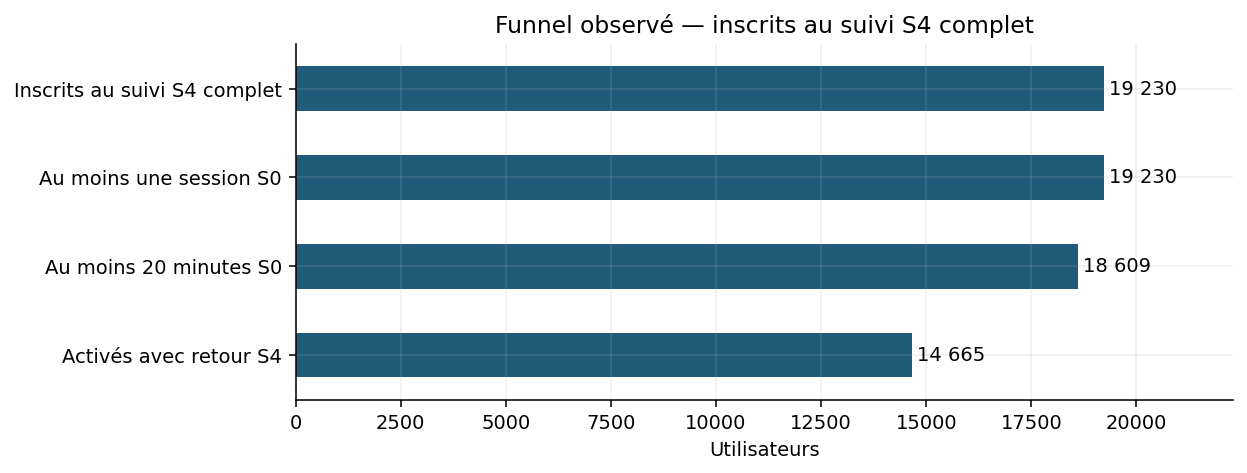

In [12]:
LISTENING_THRESHOLD = 20
activation["activated"] = activation["listening_minutes"].ge(LISTENING_THRESHOLD).astype("boolean")
activation.loc[activation["listening_minutes"].isna(), "activated"] = pd.NA
initial = activation.loc[observable(activation, 0)]
print("Activation sur les inscriptions dont S0 est complète :")
print("Inscrits :", len(initial), "| Activés :", int(initial["activated"].sum()), "| Indéterminés :", int(initial["activated"].isna().sum()))
print("Taux parmi les cas connus :", round(100 * initial["activated"].mean(), 2), "%")

funnel_population = activation.loc[observable(activation, 4)].copy()
funnel_population["returned_s4"] = returned(funnel_population, 4)
yes = funnel_population["activated"].fillna(False)
funnel = pd.Series({
    "Inscrits au suivi S4 complet": len(funnel_population),
    "Au moins une session S0": int(funnel_population["sessions"].ge(1).sum()),
    "Au moins 20 minutes S0": int(yes.sum()),
    "Activés avec retour S4": int((yes & funnel_population["returned_s4"]).sum()),
})
print("\nFunnel :")
print(funnel.to_string())
print("Activation indéterminée :", int(funnel_population["activated"].isna().sum()))
print("Retour S4 de tous les inscrits, activés ou non :", int(funnel_population["returned_s4"].sum()))
fig, ax = plt.subplots(figsize=(9, 3.5))
funnel.iloc[::-1].plot.barh(ax=ax, color="#215b7a")
ax.set_xlabel("Utilisateurs")
ax.set_title("Funnel observé — inscrits au suivi S4 complet")
for i, value in enumerate(funnel.iloc[::-1]):
    ax.text(value + 120, i, f"{value:,}".replace(",", " "), va="center")
ax.set_xlim(0, len(funnel_population) * 1.16)
fig.tight_layout()
plt.show()


### Rétention et pertes

Retour S4 = inscrits avec au moins une session en S4 / inscrits dont S4 est entièrement observable. Pour une inscription le 8 janvier 2025, S0 commence le 6 janvier et S4 couvre le 3 au 9 février. Être présent en S4 ne signifie pas avoir été présent toutes les semaines précédentes.

Une cohorte regroupe les inscrits d'un même mois. Chaque case ci-dessous conserve tous ses inscrits et reste vide si l'horizon est incomplet pour certains. Le retour S1 vaut 100 % dans cet extrait : il ne départage pas les critères d'activation.


Rétention en %, dénominateur = tous les inscrits de la cohorte :
                    S0             S1             S2             S4             S8            S12
cohorte                                                                                          
2025-01          100.0          100.0           91.8           79.6           63.7           54.3
2025-02          100.0          100.0           93.1           80.7           62.8           52.7
2025-03          100.0          100.0           92.0           80.0           61.3           51.7
2025-04          100.0          100.0           91.4           78.6           61.5           50.2
2025-05          100.0          100.0           91.3           77.6           59.1           48.8
2025-06          100.0          100.0           91.4           78.0           60.3           50.7
2025-07          100.0          100.0           92.1           78.8           61.8           51.6
2025-08          100.0          100.0           90.1 

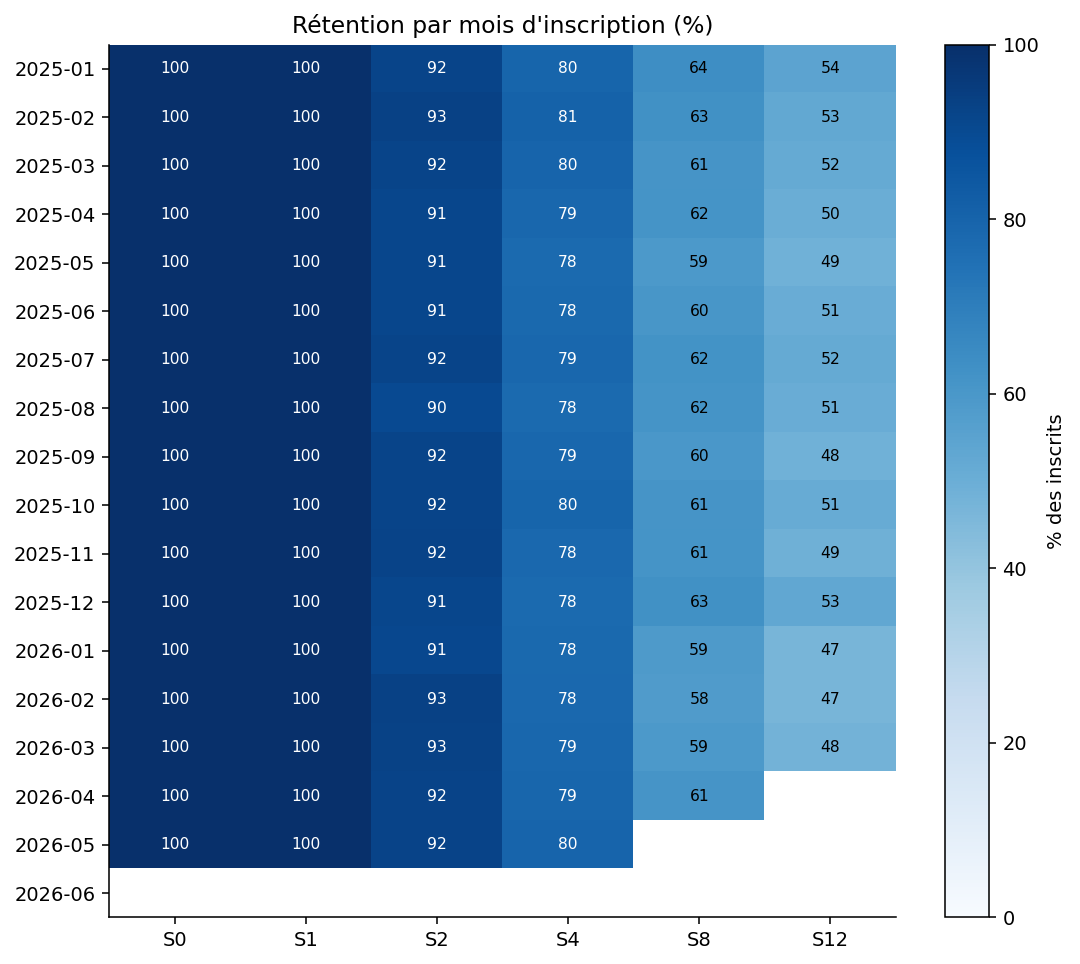

In [13]:
horizons = [0, 1, 2, 4, 8, 12]
retention = pd.DataFrame(index=sorted(users["cohort"].unique()), columns=horizons, dtype=float)
retention.index.name = "cohorte"
for cohort, group in users.groupby("cohort"):
    for age in horizons:
        if observable(group, age).all():
            retention.loc[cohort, age] = 100 * returned(group, age).mean()
print("Rétention en %, dénominateur = tous les inscrits de la cohorte :")
print(retention.round(1).rename(columns=lambda age: f"S{age}").to_string(na_rep="non observable"))
print("\nPertes à horizon observable, tous canaux :")
for age in [1, 4, 8, 12]:
    group = users.loc[observable(users, age)]
    n_returned = int(returned(group, age).sum())
    print(f"S{age} : {n_returned}/{len(group)} actifs ({100*n_returned/len(group):.1f} %), {len(group)-n_returned} sans activité enregistrée.")

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(retention.to_numpy(), vmin=0, vmax=100, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(horizons)), [f"S{x}" for x in horizons])
ax.set_yticks(range(len(retention)), retention.index)
ax.set_title("Rétention par mois d'inscription (%)")
ax.grid(False)
for row in range(len(retention)):
    for col in range(len(horizons)):
        value = retention.iloc[row, col]
        if pd.notna(value):
            ax.text(col, row, f"{value:.0f}", ha="center", va="center", color="white" if value > 65 else "black", fontsize=8)
fig.colorbar(image, ax=ax, label="% des inscrits")
fig.tight_layout()
plt.show()


### Canaux et segments comparables

On compare d'abord tous les utilisateurs à la même ancienneté, S4. Puis on calcule la rétention de chaque canal dans chaque groupe « mois d'inscription × plateforme ». On fait la moyenne de ces taux avec les mêmes poids pour tous les canaux, selon la répartition de la population commune. C'est le taux ajusté : les canaux sont comparés comme s'ils avaient le même mélange de mois et de plateformes.

Pour comparer les plateformes, on ajuste sur le mois et le canal ; pour l'âge, sur le mois, le canal et la plateforme. Cela réduit les différences de composition observées, sans prouver un effet causal.

Hypothèse à tester : une publicité peut attirer un essai par curiosité, tandis qu'une recherche dans le store ou une promotion dans un podcast peut refléter un intérêt préalable pour l'audio. Les données ne renseignent pas les motivations ni les créations publicitaires : cette explication reste une hypothèse.


acquisition_channel : 34/34 strates communes
                     utilisateurs  retention_brute_pct  retention_ajustee_pct  utilisateurs_strates_communes
acquisition_channel                                                                                         
organic_store                7100                83.34                  83.35                           7100
paid_social                  8262                71.35                  71.35                           8262
podcast_cross_promo          3868                86.25                  86.21                           3868

platform : 51/51 strates communes
          utilisateurs  retention_brute_pct  retention_ajustee_pct  utilisateurs_strates_communes
platform                                                                                         
Android           9644                78.86                  78.89                           9644
iOS               9586                78.69                  78.63               

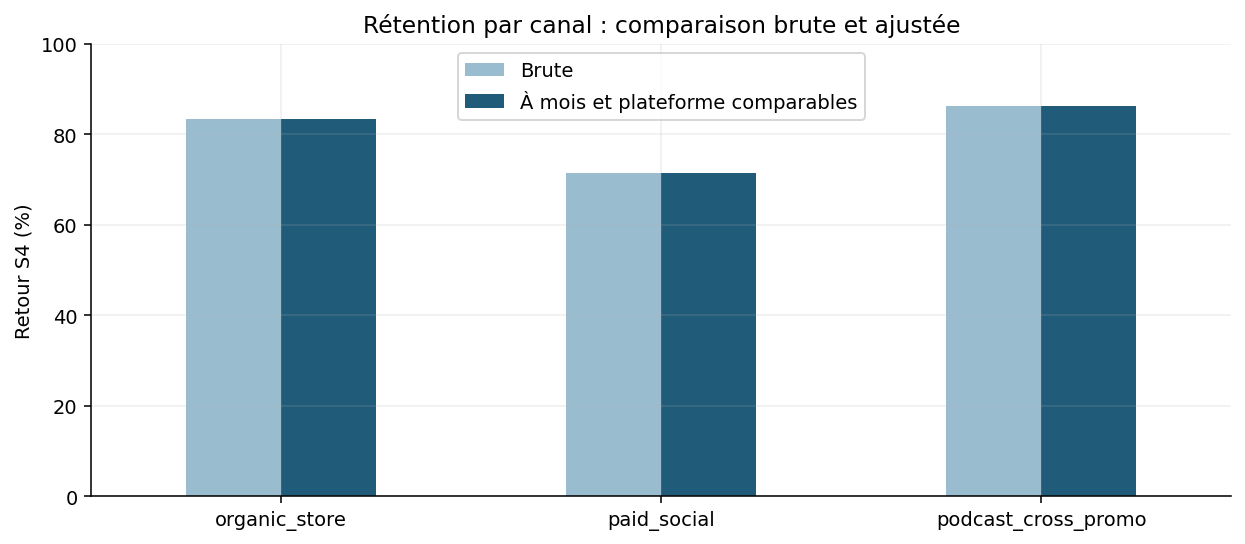

In [14]:
segments = users.loc[observable(users, 4)].copy()
segments["returned_s4"] = returned(segments, 4)

def compare_segments(frame, group_column, strata):
    crude = frame.groupby(group_column)["returned_s4"].agg(["size", "mean"])
    grouped = frame.groupby(strata + [group_column])["returned_s4"].agg(["size", "mean"])
    rates = grouped["mean"].unstack(group_column)
    counts = grouped["size"].unstack(group_column)
    common = rates.notna().all(axis=1)
    weights = counts.loc[common].sum(axis=1)
    weights = weights / weights.sum()
    adjusted = rates.loc[common].mul(weights, axis=0).sum(axis=0)
    result = crude.rename(columns={"size": "utilisateurs", "mean": "retention_brute_pct"})
    result["retention_brute_pct"] *= 100
    result["retention_ajustee_pct"] = adjusted * 100
    result["utilisateurs_strates_communes"] = counts.loc[common].sum(axis=0)
    print(f"{group_column} : {int(common.sum())}/{len(common)} strates communes")
    print(result.round(2).to_string())
    return result

channel_comparison = compare_segments(segments, "acquisition_channel", ["cohort", "platform"])
print()
platform_comparison = compare_segments(segments, "platform", ["cohort", "acquisition_channel"])
print()
age_comparison = compare_segments(segments, "age_bucket", ["cohort", "acquisition_channel", "platform"])
fig, ax = plt.subplots()
channel_comparison[["retention_brute_pct", "retention_ajustee_pct"]].plot.bar(ax=ax, color=["#9abccf", "#215b7a"], rot=0)
ax.set_ylabel("Retour S4 (%)")
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.set_title("Rétention par canal : comparaison brute et ajustée")
ax.legend(["Brute", "À mois et plateforme comparables"])
fig.tight_layout()
plt.show()


### Évolution sur les 18 mois

Les graphiques hebdomadaires excluent les semaines du 30 décembre 2024 et du 29 juin 2026, car elles dépassent les bornes de l'extrait. Les revenus sont rattachés à la semaine, sans répartition artificielle entre mois. La croissance de la base active peut venir de l'accumulation des cohortes : on la lit avec la rétention.

La période d'inscription au test push va du 15 janvier au 15 mars 2026, d'après le data pack. Une évolution à cette période ne prouve pas un effet des notifications ; l'analyse randomisée sera faite à l'étape 5.

Inscriptions mensuelles par canal :
acquisition_channel  organic_store  paid_social  podcast_cross_promo
cohort                                                              
2025-01                        300          380                  150
2025-02                        312          391                  157
2025-03                        324          403                  165
2025-04                        337          415                  173
2025-05                        350          427                  182
2025-06                        364          440                  191
2025-07                        379          453                  201
2025-08                        394          467                  211
2025-09                        410          481                  221
2025-10                        426          495                  232
2025-11                        444          510                  244
2025-12                        461          526                  25

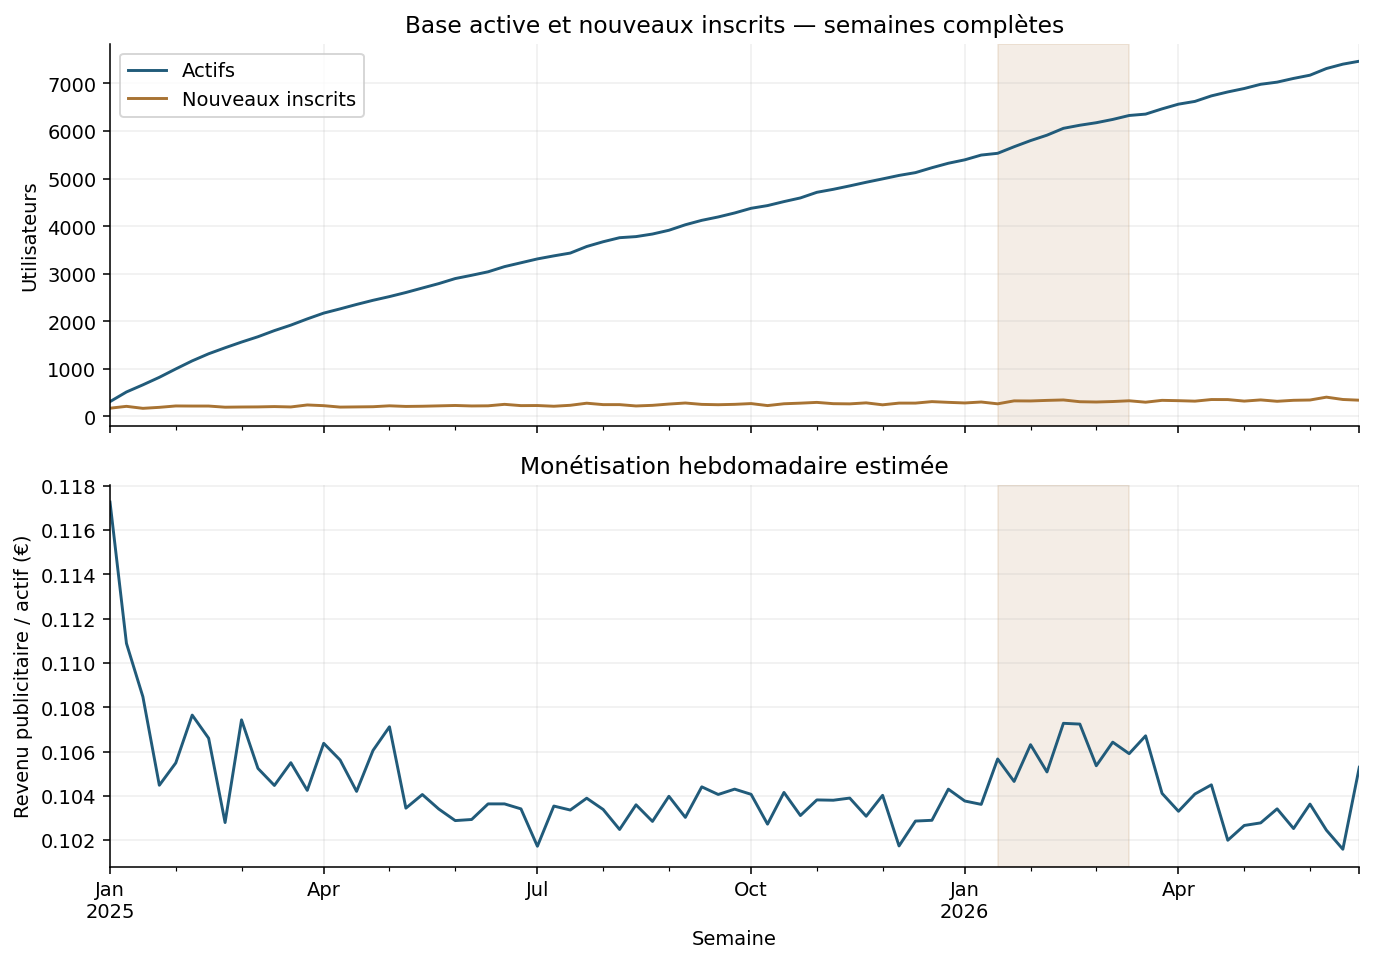

In [15]:
complete_activity = activity.loc[activity["week_start"].ge("2025-01-01") & activity["week_start"].add(pd.Timedelta(days=6)).le(cutoff)]
weekly = complete_activity.groupby("week_start").agg(
    active_users=("user_id", "nunique"), sessions=("sessions", "sum"),
    ad_revenue_eur=("ad_revenue_eur", "sum"), mean_minutes=("listening_minutes", "mean"),
)
weekly["new_users"] = users.groupby("signup_week").size().reindex(weekly.index, fill_value=0)
weekly["revenue_per_active"] = weekly["ad_revenue_eur"] / weekly["active_users"]
monthly_signups = users.groupby(["cohort", "acquisition_channel"]).size().unstack(fill_value=0)
print("Inscriptions mensuelles par canal :")
print(monthly_signups.to_string())
print("\nPremière et dernière semaines complètes :")
print(weekly.iloc[[0, -1]].round(3).to_string())
print("\nRetour S4 par mois d'inscription (cohortes entièrement observables) :")
print(retention[4].dropna().round(2).to_string())

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
weekly[["active_users", "new_users"]].plot(ax=axes[0], color=["#215b7a", "#a87333"])
axes[0].set_title("Base active et nouveaux inscrits — semaines complètes")
axes[0].set_ylabel("Utilisateurs")
axes[0].legend(["Actifs", "Nouveaux inscrits"])
weekly["revenue_per_active"].plot(ax=axes[1], color="#215b7a")
axes[1].set_ylabel("Revenu publicitaire / actif (€)")
axes[1].set_xlabel("Semaine")
axes[1].set_title("Monétisation hebdomadaire estimée")
for ax in axes:
    ax.axvspan(pd.Timestamp("2026-01-15"), pd.Timestamp("2026-03-15"), color="#a87333", alpha=0.12)
fig.tight_layout()
plt.show()


### Coût d'acquisition et revenus

CAC = dépense d'acquisition / nouveaux inscrits du canal. Seul paid_social a des dépenses renseignées. Le coût de mai 2025 est estimé ; les autres canaux ont un coût inconnu, pas nul.

Revenu par inscrit sur douze semaines = impressions publicitaires S0–S11 × 9 €/1 000 / inscrits de la cohorte, inactifs compris. On conserve les cohortes entièrement observables. S0 peut être partielle : ce ne sont pas exactement les 84 premiers jours individuels.

Pour paid_social, environ 0,84 € de revenu / 2,61 € de CAC = 32,4 % du coût d'acquisition récupéré à cet horizon. Ce n'est ni une marge ni un bénéfice. Le revenu futur est encore inconnu ; ce montant n'est pas une LTV totale.

Le payback brut est la première semaine où le revenu cumulé de la cohorte couvre sa dépense d'acquisition. Le suivi s'arrête au dernier âge entièrement observable pour tous ses inscrits. « Non atteint pendant le suivi » ne signifie pas « jamais atteint ». Les coûts d'exploitation manquent : on ne peut pas calculer la rentabilité nette.


In [16]:
acquisitions = users.groupby(["cohort", "acquisition_channel"]).size().rename("new_users").reset_index()
spend_by_cohort = spend.assign(cohort=spend["month"].dt.to_period("M").astype(str)).rename(columns={"channel": "acquisition_channel"})
cac = acquisitions.merge(spend_by_cohort[["cohort", "acquisition_channel", "spend_eur", "spend_is_estimated"]], on=["cohort", "acquisition_channel"], how="left", validate="one_to_one")
cac["cac_eur"] = cac["spend_eur"] / cac["new_users"]
paid_cac = cac.loc[cac["acquisition_channel"].eq("paid_social")].copy()
print("CAC paid_social par mois (EUR) :")
print(paid_cac[["cohort", "new_users", "spend_eur", "spend_is_estimated", "cac_eur"]].rename(columns={"cohort": "Mois", "new_users": "Nouveaux_inscrits", "spend_eur": "Depense_EUR", "spend_is_estimated": "Estimation", "cac_eur": "CAC_EUR"}).round(3).to_string(index=False))

cohort_end_weeks = users.groupby("cohort")["signup_week"].max()
fully_observed_12 = cohort_end_weeks.index[cohort_end_weeks.add(pd.Timedelta(days=11 * 7 + 6)).le(cutoff)]
eligible_12 = users.loc[users["cohort"].isin(fully_observed_12)].copy()
revenue_12 = activity.loc[activity["cohort"].isin(fully_observed_12) & activity["age_week"].between(0, 11)].groupby("user_id")["ad_revenue_eur"].sum()
eligible_12["revenue_s0_s11_eur"] = eligible_12["user_id"].map(revenue_12).fillna(0)
cohort_economics = eligible_12.groupby(["cohort", "acquisition_channel"]).agg(users=("user_id", "size"), revenue_s0_s11_eur=("revenue_s0_s11_eur", "mean")).reset_index()
cohort_economics = cohort_economics.merge(cac[["cohort", "acquisition_channel", "cac_eur", "spend_is_estimated"]], on=["cohort", "acquisition_channel"], validate="one_to_one")
print("\nRevenu publicitaire S0-S11 par inscrit et par cohorte (EUR) :")
print(cohort_economics.pivot(index="cohort", columns="acquisition_channel", values="revenue_s0_s11_eur").round(3).to_string())

channel_economics = eligible_12.groupby("acquisition_channel").agg(users=("user_id", "size"), revenue_s0_s11_eur=("revenue_s0_s11_eur", "mean"))
eligible_paid_cac = paid_cac.loc[paid_cac["cohort"].isin(fully_observed_12)]
channel_economics["cac_eur"] = float("nan")
channel_economics.loc["paid_social", "cac_eur"] = eligible_paid_cac["spend_eur"].sum() / eligible_paid_cac["new_users"].sum()
channel_economics["revenue_12w_over_cac"] = channel_economics["revenue_s0_s11_eur"] / channel_economics["cac_eur"]
print("\nSynthèse sur les mêmes cohortes entièrement observables à 12 semaines :")
print(channel_economics.rename(columns={"users": "Inscrits", "revenue_s0_s11_eur": "Revenu_12_sem_par_inscrit_EUR", "cac_eur": "CAC_EUR", "revenue_12w_over_cac": "Part_CAC_recuperee"}).round(3).to_string(na_rep="inconnu"))

payback_rows = []
for row in paid_cac.itertuples(index=False):
    max_age = (int((cutoff - cohort_end_weeks.loc[row.cohort]).days) - 6) // 7
    if max_age < 0:
        payback_rows.append({"cohort": row.cohort, "semaines_observees": 0, "payback_semaines": float("nan"), "statut": "suivi incomplet", "depense_estimee": row.spend_is_estimated, "revenu_sur_depense": float("nan")})
        continue
    cohort_revenue = activity.loc[activity["cohort"].eq(row.cohort) & activity["acquisition_channel"].eq("paid_social") & activity["age_week"].between(0, max_age)]
    cumulative = cohort_revenue.groupby("age_week")["ad_revenue_eur"].sum().reindex(range(max_age + 1), fill_value=0).cumsum()
    recovered = cumulative.index[cumulative.ge(row.spend_eur)]
    payback_rows.append({"cohort": row.cohort, "semaines_observees": max_age + 1, "payback_semaines": int(recovered[0]) + 1 if len(recovered) else float("nan"), "statut": "atteint" if len(recovered) else "non atteint pendant le suivi", "depense_estimee": row.spend_is_estimated, "revenu_sur_depense": cumulative.iloc[-1] / row.spend_eur})
payback = pd.DataFrame(payback_rows)
print("\nRécupération publicitaire brute par cohorte paid_social :")
print(payback.round(3).to_string(index=False, na_rep="—"))
print("\nSensibilité : CAC agrégé à 12 semaines hors mai 2025 estimé :", round(eligible_paid_cac.loc[eligible_paid_cac["spend_is_estimated"].eq(False), "spend_eur"].sum() / eligible_paid_cac.loc[eligible_paid_cac["spend_is_estimated"].eq(False), "new_users"].sum(), 3), "EUR")
assert len(eligible_12) == cohort_economics["users"].sum()
assert channel_economics.loc[["organic_store", "podcast_cross_promo"], "cac_eur"].isna().all()
assert (payback["payback_semaines"].dropna() <= payback.loc[payback["payback_semaines"].notna(), "semaines_observees"]).all()


CAC paid_social par mois (EUR) :
   Mois  Nouveaux_inscrits  Depense_EUR Estimation  CAC_EUR
2025-01                380        990.0      False    2.605
2025-02                391       1020.0      False    2.609
2025-03                403       1050.0      False    2.605
2025-04                415       1080.0      False    2.602
2025-05                427       1115.0       True    2.611
2025-06                440       1150.0      False    2.614
2025-07                453       1180.0      False    2.605
2025-08                467       1220.0      False    2.612
2025-09                481       1250.0      False    2.599
2025-10                495       1290.0      False    2.606
2025-11                510       1330.0      False    2.608
2025-12                526       1370.0      False    2.605
2026-01                541       1410.0      False    2.606
2026-02                558       1450.0      False    2.599
2026-03                574       1490.0      False    2.596
2026-04

### North Star Metric

On retient les minutes totales d'écoute par semaine : la quantité de contenu réellement consommée, plutôt que les ouvertures de l'app. Le total peut croître avec l'audience sans amélioration individuelle. On le lit avec les actifs, la rétention, la moyenne, la médiane et les notifications reçues par actif.

Seules les durées connues sont additionnées ; leur couverture est affichée. Les durées manquantes ne sont pas remplacées par zéro. Les semaines incomplètes sont exclues.

Le choix est cohérent avec l'audio : [Amplitude utilise le temps d'écoute dans son exemple Spotify](https://info.amplitude.com/rs/138-CDN-550/images/North-Star_how-to-Guide_2024.pdf), sans que cet exemple établisse une métrique officielle unique du marché. [Spotify publie aussi des heures d'écoute](https://newsroom.spotify.com/2026-05-21/investor-day-recap/). Plus de temps ne prouve toutefois pas, à lui seul, plus de satisfaction.


Première et dernière semaines complètes :
            listening_minutes  mean_known_minutes  median_known_minutes  active_users  known_durations  push_received  coverage_pct  push_per_active
week_start                                                                                                                                          
2025-01-06            28618.0               91.72                 81.85           312              312           1244        100.00             3.99
2026-06-22           618332.1               82.92                 70.60          7468             7457          40299         99.85             5.40

Couverture minimale des durées connues : 99.61 %


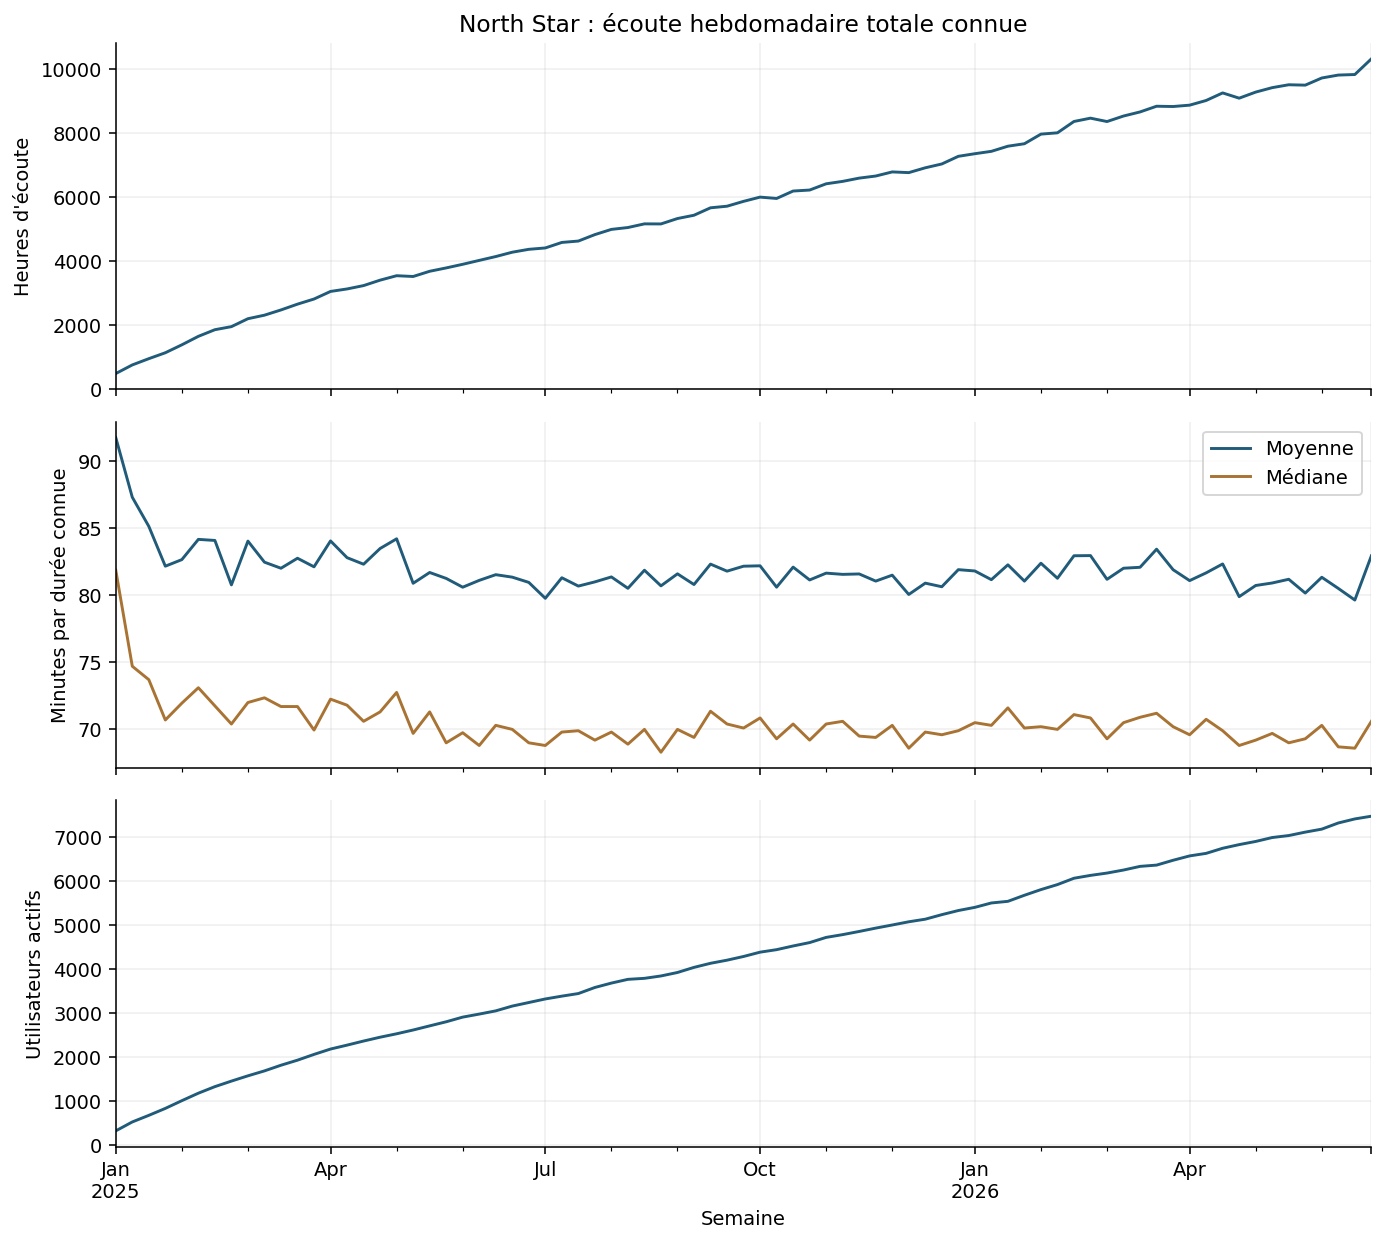

In [17]:
north_star = complete_activity.groupby("week_start").agg(
    listening_minutes=("listening_minutes", lambda s: s.sum(min_count=1)),
    mean_known_minutes=("listening_minutes", "mean"), median_known_minutes=("listening_minutes", "median"),
    active_users=("user_id", "nunique"), known_durations=("listening_minutes", "count"),
    push_received=("push_notifications_received", "sum"),
)
north_star["coverage_pct"] = 100 * north_star["known_durations"] / north_star["active_users"]
north_star["push_per_active"] = north_star["push_received"] / north_star["active_users"]
print("Première et dernière semaines complètes :")
print(north_star.iloc[[0, -1]].round(2).to_string())
print("\nCouverture minimale des durées connues :", round(north_star["coverage_pct"].min(), 2), "%")
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
north_star["listening_minutes"].div(60).plot(ax=axes[0], color="#215b7a")
axes[0].set_title("North Star : écoute hebdomadaire totale connue")
axes[0].set_ylabel("Heures d'écoute")
north_star[["mean_known_minutes", "median_known_minutes"]].plot(ax=axes[1], color=["#215b7a", "#a87333"])
axes[1].set_ylabel("Minutes par durée connue")
axes[1].legend(["Moyenne", "Médiane"])
north_star["active_users"].plot(ax=axes[2], color="#215b7a")
axes[2].set_ylabel("Utilisateurs actifs")
axes[2].set_xlabel("Semaine")
fig.tight_layout()
plt.show()
assert north_star["coverage_pct"].between(0, 100).all()


### Ce que l'on retient

- La base active et les inscriptions augmentent. Les cohortes perdent toutefois des utilisateurs avec l'ancienneté : la hausse de la base ne prouve pas une amélioration de la rétention.
- Le retour S4 de paid_social est plus faible que celui des deux autres canaux, même à mois d'inscription et plateforme comparables. Ce constat ne prouve pas que le canal cause la différence.
- Les différences entre plateformes sont faibles. Une partie des écarts bruts entre âges vient de la composition des groupes.
- L'activation retenue est une écoute d'au moins vingt minutes pendant S0. La règle est simple et liée au contenu consommé ; le seuil est une convention, pas un prédicteur démontré de fidélité. Elle n'exige pas un retour S4.
- Les minutes totales connues augmentent avec l'audience, sans hausse comparable de l'écoute moyenne par actif. Les notifications seront jugées aussi sur l'écoute et la rétention, pas seulement sur les ouvertures.
- Sur les cohortes entièrement observables à douze semaines, paid_social génère environ 0,84 € de revenu publicitaire par inscrit pour un CAC de 2,61 €, soit 32,4 % du CAC récupéré à cet horizon. Aucun payback brut n’est atteint sur les horizons communs observés ; cela ne prouve pas qu’il ne sera jamais atteint. La LTV complète et la rentabilité restent à estimer avec des hypothèses explicites.

L'étape 5 évaluera le test randomisé de notifications. Le diagnostic présent ne suffit pas à attribuer les évolutions aux notifications ni à recommander leur généralisation.


## Test des notifications

Le data pack décrit une répartition aléatoire des nouveaux inscrits du 15 janvier au 15 mars 2026 entre `control` et `aggressive_push`. `standard` ne fait pas partie du test. On garde tous les participants selon leur groupe assigné, même s'ils deviennent inactifs. On ne sélectionne pas les activés ou les survivants.

La mesure principale est l'écoute cumulée par utilisateur assigné pendant S1–S12 : douze semaines calendaires complètes après la semaine d'inscription. S0 est partielle et reste hors de cette mesure. Les sessions, revenus publicitaires, semaines actives et retours S4/S8/S12 sont secondaires. Les revenus sont estimés au CPM de 9 €.

Les contrôles initiaux utilisent uniquement des caractéristiques à l'inscription : plateforme, canal, âge et date. Le nombre d'émissions suivies pendant la première semaine peut déjà être influencé par le traitement ; il ne sert pas à ajuster les groupes.
La période d'assignation et la période de suivi sont différentes : la fin de S12 va du 12 avril au 7 juin selon la date d'inscription. Les données continuent jusqu'au 30 juin.


In [18]:
import numpy as np

trial = users.loc[users["push_variant"].isin(["control", "aggressive_push"])].copy()
assert trial["user_id"].is_unique
assert trial["signup_date"].between("2026-01-15", "2026-03-15").all()
assert observable(trial, 12).all()
assigned = trial["push_variant"].value_counts().reindex(["control", "aggressive_push"])
print("Participants assignés :")
print(assigned.to_string())
print("\nDates d'inscription :")
print(trial.groupby("push_variant")["signup_date"].agg(["min", "max"]).to_string())
for column in ["platform", "acquisition_channel", "age_bucket"]:
    print(f"\n{column} — répartition dans chaque groupe (%) :")
    print((pd.crosstab(trial[column], trial["push_variant"], normalize="columns") * 100).round(1).to_string())


Participants assignés :
push_variant
control            1366
aggressive_push    1343

Dates d'inscription :
                       min        max
push_variant                         
aggressive_push 2026-01-15 2026-03-15
control         2026-01-15 2026-03-15

platform — répartition dans chaque groupe (%) :
push_variant  aggressive_push  control
platform                              
Android                  48.8     49.9
iOS                      51.2     50.1

acquisition_channel — répartition dans chaque groupe (%) :
push_variant         aggressive_push  control
acquisition_channel                          
organic_store                   38.3     37.6
paid_social                     40.3     42.0
podcast_cross_promo             21.4     20.4

age_bucket — répartition dans chaque groupe (%) :
push_variant  aggressive_push  control
age_bucket                            
18-24                    26.5     29.8
25-34                    35.4     33.0
35-44                    18.8     19.7

### Mesures par participant

On cumule d'abord les mesures de chaque personne, puis on compare les moyennes des groupes. Une semaine sans activité enregistrée apporte zéro session, écoute et impression publicitaire. Une durée manquante sur une ligne existante reste inconnue. On présente donc l'écoute connue, sa couverture et des analyses de sensibilité.

Le retour à chaque horizon est un oui/non par personne. Chaque participant compte une seule fois par mesure, quel que soit son nombre de sessions.

In [19]:
trial_activity = activity.loc[activity["user_id"].isin(trial["user_id"])].copy()
followup = trial_activity.loc[trial_activity["age_week"].between(1, 12)].copy()
totals = followup.groupby("user_id").agg(
    minutes_known=("listening_minutes", "sum"), sessions=("sessions", "sum"),
    revenue_eur=("ad_revenue_eur", "sum"), active_weeks=("week_start", "size"),
    missing_durations=("listening_minutes", lambda s: s.isna().sum()),
)
outcomes = trial.merge(totals, on="user_id", how="left", validate="one_to_one")
sum_columns = ["minutes_known", "sessions", "revenue_eur", "active_weeks", "missing_durations"]
outcomes[sum_columns] = outcomes[sum_columns].fillna(0)
for age in [4, 8, 12]:
    outcomes[f"return_s{age}"] = returned(outcomes, age).astype(float)
coverage = followup.groupby("push_variant").agg(
    active_rows=("user_id", "size"), known_durations=("listening_minutes", "count"),
)
coverage["missing_durations"] = coverage["active_rows"] - coverage["known_durations"]
coverage["known_pct"] = 100 * coverage["known_durations"] / coverage["active_rows"]
coverage["affected_users"] = outcomes.assign(affected=outcomes["missing_durations"].gt(0)).groupby("push_variant")["affected"].sum()
print("Couverture des durées sur les semaines actives :")
print(coverage.round(3).to_string())
print("\nToutes les semaines absentes restent incluses dans les dénominateurs des participants assignés.")
assert len(outcomes) == len(trial)
assert outcomes["active_weeks"].between(0, 12).all()
assert len(followup) == outcomes["active_weeks"].sum()
assert followup["listening_minutes"].isna().sum() == 20

notifications_observed = followup.groupby("push_variant")["push_notifications_received"].mean()
print("\nNotifications renseignées par semaine active, S1-S12 :")
print(notifications_observed.round(2).to_string())
print("Cette moyenne ne mesure pas l'exposition des semaines inactives.")


Couverture des durées sur les semaines actives :
                 active_rows  known_durations  missing_durations  known_pct  affected_users
push_variant                                                                               
aggressive_push        10450            10442                  8     99.923               8
control                11539            11527                 12     99.896              12

Toutes les semaines absentes restent incluses dans les dénominateurs des participants assignés.

Notifications renseignées par semaine active, S1-S12 :
push_variant
aggressive_push    32.00
control             4.04
Cette moyenne ne mesure pas l'exposition des semaines inactives.


### Écarts et incertitude

Les écarts sont « agressif moins contrôle ». Les intervalles à 95 % sont obtenus par 5 000 rééchantillonnages des utilisateurs, séparément dans chaque groupe. Toutes les semaines d'une personne restent ensemble. Un intervalle qui traverse zéro ne permet pas de conclure clairement sur le sens de l'effet.

Les intervalles des mesures secondaires ne sont pas corrigés pour les comparaisons multiples : ils servent à interpréter les bénéfices et risques, sans chercher un résultat favorable parmi de nombreux tests. Les minutes connues constituent un cumul incomplet pour les vingt participants concernés par une durée manquante.

In [20]:
def bootstrap_difference(control, aggressive, repeats=5000, seed=20261108):
    control = np.asarray(control, dtype=float)
    aggressive = np.asarray(aggressive, dtype=float)
    if control.ndim == 1:
        control = control[:, None]
        aggressive = aggressive[:, None]
    rng = np.random.default_rng(seed)
    draws = np.empty((repeats, control.shape[1]))
    for start in range(0, repeats, 200):
        size = min(200, repeats - start)
        c = control[rng.integers(0, len(control), (size, len(control)))].mean(axis=1)
        a = aggressive[rng.integers(0, len(aggressive), (size, len(aggressive)))].mean(axis=1)
        draws[start:start + size] = a - c
    return np.quantile(draws, [0.025, 0.975], axis=0)

metrics = {
    "minutes_known": ("Minutes connues S1–S12", "minutes", 1),
    "sessions": ("Sessions S1–S12", "sessions", 1),
    "revenue_eur": ("Revenu publicitaire S1–S12", "EUR", 1),
    "active_weeks": ("Semaines actives S1–S12", "semaines", 1),
    "return_s4": ("Retour S4", "points de %", 100),
    "return_s8": ("Retour S8", "points de %", 100),
    "return_s12": ("Retour S12", "points de %", 100),
}
control = outcomes.loc[outcomes["push_variant"].eq("control"), list(metrics)]
aggressive = outcomes.loc[outcomes["push_variant"].eq("aggressive_push"), list(metrics)]
bounds = bootstrap_difference(control, aggressive)
effect_rows = []
for index, (column, (label, unit, scale)) in enumerate(metrics.items()):
    c = control[column].mean()
    a = aggressive[column].mean()
    effect_rows.append({"Mesure": label, "Unité écart": unit, "Contrôle": c * scale, "Agressif": a * scale,
        "Écart": (a - c) * scale, "IC95 bas": bounds[0, index] * scale, "IC95 haut": bounds[1, index] * scale,
        "Évolution relative (%)": (a / c - 1) * 100 if scale == 1 else np.nan})
effects = pd.DataFrame(effect_rows)
print(effects.round(3).to_string(index=False, na_rep="—"))
print("\nPour les retours, les colonnes Contrôle et Agressif sont des pourcentages ; l'écart est en points de pourcentage.")


                    Mesure Unité écart  Contrôle  Agressif   Écart  IC95 bas  IC95 haut  Évolution relative (%)
    Minutes connues S1–S12     minutes   680.198   644.510 -35.689   -62.835     -9.614                  -5.247
           Sessions S1–S12    sessions    29.068    31.601   2.533     1.384      3.651                   8.713
Revenu publicitaire S1–S12         EUR     0.865     0.876   0.010    -0.024      0.043                   1.199
   Semaines actives S1–S12    semaines     8.447     7.781  -0.666    -0.983     -0.361                  -7.887
                 Retour S4 points de %    78.697    78.034  -0.663    -3.679      2.430                       —
                 Retour S8 points de %    62.225    52.048 -10.178   -13.881     -6.441                       —
                Retour S12 points de %    51.318    39.613 -11.705   -15.479     -8.100                       —

Pour les retours, les colonnes Contrôle et Agressif sont des pourcentages ; l'écart est en points de po

### Sensibilité aux vingt durées manquantes

Les CSV nettoyés ne changent pas. Pour cette vérification seulement, on estime chaque durée manquante par la médiane des valeurs du même groupe, à la même ancienneté et avec le même nombre de sessions. Si cette cellule contient moins de dix observations, on utilise la médiane du même groupe et du même nombre de sessions.

On compare aussi les utilisateurs sans aucune durée manquante. Cette exclusion sert uniquement de sensibilité : elle n'est pas la comparaison principale selon l'assignation initiale. Les intervalles avec estimation sont conditionnels à cette règle ; ils n'intègrent pas toute l'incertitude des valeurs manquantes.

In [21]:
valid = followup.loc[followup["listening_minutes"].notna()]
detail_keys = ["push_variant", "age_week", "sessions"]
medians = valid.groupby(detail_keys)["listening_minutes"].agg(["median", "count"])
matched = medians.reindex(pd.MultiIndex.from_frame(followup[detail_keys]))
fallback = valid.groupby(["push_variant", "sessions"])["listening_minutes"].median().reindex(pd.MultiIndex.from_frame(followup[["push_variant", "sessions"]])).to_numpy()
estimates = np.where(matched["count"].to_numpy() >= 10, matched["median"].to_numpy(), fallback)
analysis_minutes = followup["listening_minutes"].fillna(pd.Series(estimates, index=followup.index))
assert analysis_minutes.notna().all()
estimated_totals = analysis_minutes.groupby(followup["user_id"]).sum()
outcomes["minutes_estimated_sensitivity"] = outcomes["user_id"].map(estimated_totals).fillna(0)
sensitivity_rows = []
for label, frame, column in [
    ("Minutes connues, tous assignés", outcomes, "minutes_known"),
    ("20 durées estimées, tous assignés", outcomes, "minutes_estimated_sensitivity"),
    ("Sans les 20 utilisateurs concernés", outcomes.loc[outcomes["missing_durations"].eq(0)], "minutes_known"),
]:
    c = frame.loc[frame["push_variant"].eq("control"), column]
    a = frame.loc[frame["push_variant"].eq("aggressive_push"), column]
    interval = bootstrap_difference(c, a)[:, 0]
    sensitivity_rows.append({"Méthode": label, "N contrôle": len(c), "N agressif": len(a),
        "Minutes contrôle": c.mean(), "Minutes agressif": a.mean(), "Écart": a.mean() - c.mean(),
        "IC95 bas": interval[0], "IC95 haut": interval[1]})
sensitivity = pd.DataFrame(sensitivity_rows)
print(sensitivity.round(2).to_string(index=False))
assert (outcomes["minutes_estimated_sensitivity"] >= outcomes["minutes_known"]).all()


                           Méthode  N contrôle  N agressif  Minutes contrôle  Minutes agressif  Écart  IC95 bas  IC95 haut
    Minutes connues, tous assignés        1366        1343            680.20            644.51 -35.69    -62.83      -9.61
 20 durées estimées, tous assignés        1366        1343            680.68            645.03 -35.65    -62.80      -9.45
Sans les 20 utilisateurs concernés        1354        1335            679.72            644.29 -35.43    -63.10      -8.09


### Évolution pendant le suivi

Chaque point utilise tous les participants assignés, pas seulement ceux encore actifs. Cela permet de distinguer une hausse d'usage initiale d'une différence durable. Les minutes restent les minutes connues. Les retours sont calculés sur des utilisateurs uniques à chaque semaine.

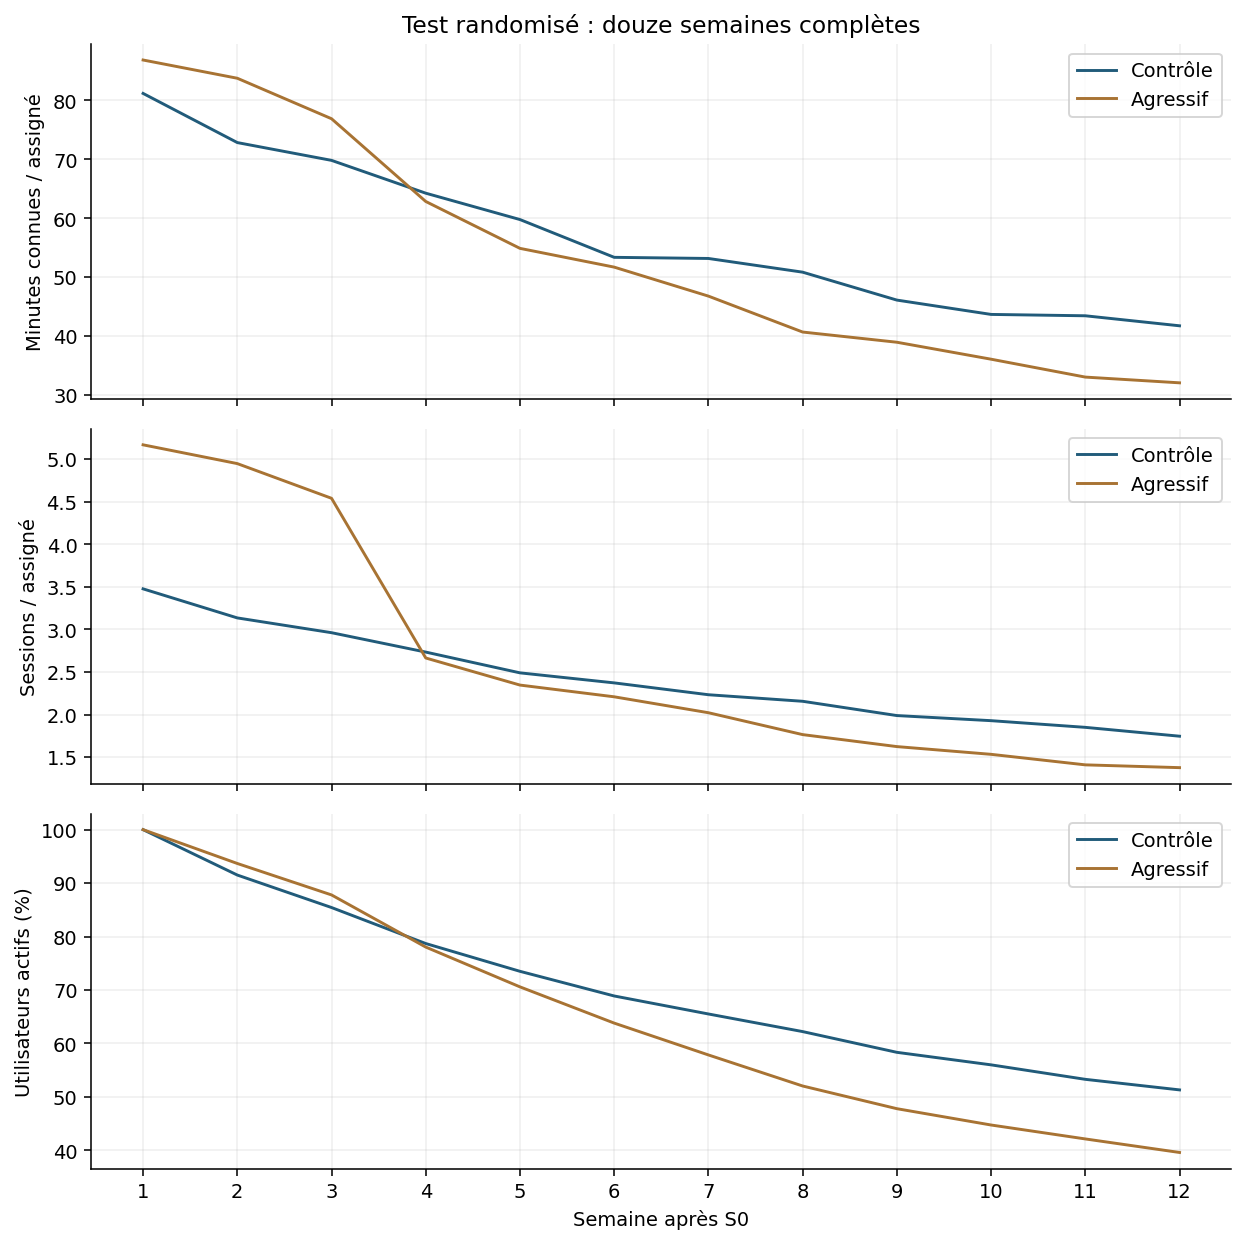

In [22]:
weekly_test = followup.groupby(["age_week", "push_variant"]).agg(
    minutes_known=("listening_minutes", "sum"), sessions=("sessions", "sum"),
    active_users=("user_id", "nunique"), revenue_eur=("ad_revenue_eur", "sum"),
).reset_index()
weekly_test["assigned"] = weekly_test["push_variant"].map(assigned)
weekly_test["minutes_per_assigned"] = weekly_test["minutes_known"] / weekly_test["assigned"]
weekly_test["sessions_per_assigned"] = weekly_test["sessions"] / weekly_test["assigned"]
weekly_test["retention_pct"] = 100 * weekly_test["active_users"] / weekly_test["assigned"]
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
for group, label, color in [("control", "Contrôle", "#215b7a"), ("aggressive_push", "Agressif", "#a87333")]:
    series = weekly_test.loc[weekly_test["push_variant"].eq(group)].set_index("age_week")
    for ax, column in zip(axes, ["minutes_per_assigned", "sessions_per_assigned", "retention_pct"]):
        ax.plot(series.index, series[column], label=label, color=color)
axes[0].set_title("Test randomisé : douze semaines complètes")
axes[0].set_ylabel("Minutes connues / assigné")
axes[1].set_ylabel("Sessions / assigné")
axes[2].set_ylabel("Utilisateurs actifs (%)")
axes[2].set_xlabel("Semaine après S0")
for ax in axes:
    ax.legend()
    ax.set_xticks(range(1, 13))
fig.tight_layout()
plt.show()
assert weekly_test["active_users"].le(weekly_test["assigned"]).all()


### Le « +30 % de sessions » annoncé

On reconstruit la période du 15 janvier au 15 mars 2026 pour les participants du test. La première ligne hebdomadaire couvre le 12 au 18 janvier, mais les participants concernés sont tous inscrits à partir du 15. On l'inclut sous l'hypothèse qu'aucune activité ne précède la création du compte. La dernière semaine couvre le 9 au 15 mars.

Les sessions totales augmentent d'environ 31,5 % : l'annonce est donc plausible, sans preuve que l'équipe a utilisé ce calcul. Ce gain pendant le recrutement ne démontre pas un bénéfice durable. Notre comparaison principale reste le suivi de douze semaines à ancienneté identique : davantage d'ouvertures, mais moins d'écoute et de retours tardifs.


In [23]:
# Reconstruction pour les seuls participants inscrits entre le 15 janvier et le 15 mars.
# Leur activité est supposée commencer après la création du compte.
period_sessions = trial_activity.loc[
    trial_activity["week_start"].between("2026-01-12", "2026-03-09")
].groupby("push_variant")["sessions"].sum().reindex(["control", "aggressive_push"])
print("Sessions du 15 janvier au 15 mars 2026 — reconstruction :")
print(period_sessions.to_string())
print("Écart des totaux :", round(100 * (period_sessions["aggressive_push"] / period_sessions["control"] - 1), 2), "%")


Sessions du 15 janvier au 15 mars 2026 — reconstruction :
push_variant
control            21178
aggressive_push    27852
Écart des totaux : 31.51 %


### Limites

Le résultat porte sur de nouveaux inscrits entre janvier et mars 2026, avec douze semaines complètes de suivi. Il ne suffit pas à prédire l'effet chez les utilisateurs anciens ou au-delà de cet horizon. L'interprétation causale repose sur la randomisation décrite dans le data pack ; l'extrait ne permet pas d'auditer le mécanisme d'assignation.

Les notifications ne sont renseignées que pendant les semaines actives : leur nombre pendant les semaines inactives est inconnu. On ne peut pas en déduire la pression totale reçue par toute la population. Les données ne mesurent ni satisfaction, ni désabonnement aux notifications, ni désinstallation.


### Résultats à retenir

- Écoute connue S1–S12 : 680,20 minutes par personne en contrôle, contre 644,51 en agressif, soit −35,69 minutes (−5,25 %). L'intervalle à 95 % de l'écart va de −62,83 à −9,61 minutes. Les deux sensibilités aux valeurs manquantes donnent la même lecture.
- Sessions : +8,71 % sur le même horizon. Davantage d'ouvertures ne se traduit donc pas par davantage d'écoute cumulée.
- Retour S4 : écart incertain. Retour S8 : −10,18 points ; retour S12 : −11,71 points. Les intervalles de ces deux derniers écarts restent négatifs.
- Revenu publicitaire estimé : environ 0,865 € par personne en contrôle et 0,876 € en agressif. L'intervalle de l'écart inclut zéro : aucun gain de revenu publicitaire n'est démontré à cet horizon.

Le test ne soutient pas une généralisation fondée uniquement sur les sessions. La fatigue liée aux notifications est une explication possible, pas un mécanisme directement mesuré. La décision stratégique sera construite avec les scénarios ; cette section rapporte les résultats, sans imposer de nouvelle politique.


## Modèle de croissance et backtest 2025

Chaque semaine, pour chaque canal : **actifs prévus = anciens actifs × maintien hebdomadaire + nouveaux inscrits**. Les cohortes restent des groupes d'inscription hebdomadaires ; le maintien retenu ne dépend pas de leur ancienneté. Il s'agit d'une prévision d'activité, pas d'une sélection des utilisateurs activés à vingt minutes.

Les nouveaux inscrits paid viennent du budget divisé par le CAC estimé. Organic et podcast suivent leurs propres tendances d'inscriptions : leurs dépenses sont inconnues et aucun budget n'est inventé. Un effet de la publicité sur ces canaux reste une hypothèse pour les scénarios, pas un effet mesuré.

L'écoute et les impressions sont estimées à partir des actifs. On distingue seulement les nouveaux inscrits de S0 des autres actifs pour leur consommation moyenne, mesurée dans l'historique. Le revenu publicitaire est estimé avec le CPM de 9 € du data pack. Le mécanisme budget/CAC reprend le [simulateur du cours](docs/IMT%20-%20Growth%20Model%20Simulator.xlsx), sans ajouter de parrainage non observé.


In [24]:
model_users = pd.read_csv("data/clean/users.csv", parse_dates=["signup_date"])
model_activity = pd.read_csv("data/clean/weekly_activity.csv", parse_dates=["week_start"])
model_spend = pd.read_csv("data/clean/marketing_spend.csv", parse_dates=["month"])
model_users["signup_week"] = model_users["signup_date"] - pd.to_timedelta(model_users["signup_date"].dt.dayofweek, unit="D")
CHANNELS = ["paid_social", "organic_store", "podcast_cross_promo"]
historical_budgets = model_spend.set_index(model_spend["month"].dt.to_period("M"))["spend_eur"]
def age_band(age):
    return "S1" if age == 1 else "S2-S4" if age <= 4 else "S5-S12" if age <= 12 else "S13+"


def fit_model(cutoff):
    cutoff = pd.Timestamp(cutoff)
    assert cutoff.dayofweek == 6, "Utiliser un dimanche pour terminer une semaine complète."
    enrolled = model_users.loc[model_users["signup_date"].le(cutoff)].copy()
    history = model_activity.loc[model_activity["week_start"].add(pd.Timedelta(days=6)).le(cutoff)].merge(
        enrolled[["user_id", "signup_week", "acquisition_channel"]], on="user_id", validate="many_to_one")
    history["age"] = history["week_start"].sub(history["signup_week"]).dt.days // 7
    month_counts = enrolled.groupby([enrolled["signup_date"].dt.to_period("M"), "acquisition_channel"]).size().unstack(fill_value=0)
    month_counts = month_counts.loc[month_counts.index.to_timestamp(how="end").normalize() <= cutoff]
    base_month = month_counts.index[0]
    trend = {}
    for channel in CHANNELS:
        slope, intercept = np.polyfit(np.arange(len(month_counts)), np.log(month_counts[channel]), 1)
        trend[channel] = (intercept, slope)
    cac = historical_budgets.reindex(month_counts.index).sum() / month_counts["paid_social"].sum()
    keys = pd.MultiIndex.from_frame(history[["user_id", "week_start"]])
    transitions = history.loc[history["week_start"].add(pd.Timedelta(days=13)).le(cutoff)].copy()
    transitions["stays"] = pd.MultiIndex.from_arrays([transitions["user_id"], transitions["week_start"] + pd.Timedelta(weeks=1)]).isin(keys)
    transitions["band"] = transitions["age"].add(1).map(age_band)
    constant = transitions.groupby("acquisition_channel")["stays"].mean().to_dict()
    by_age = transitions.groupby(["acquisition_channel", "band"])["stays"].mean().to_dict()
    history["phase"] = np.where(history["age"].eq(0), "S0", "S1+")
    intensity = history.groupby(["acquisition_channel", "phase"]).agg(minutes=("listening_minutes", "mean"), ads=("ad_impressions", "mean"))
    origin = cutoff - pd.Timedelta(days=6)
    state = history.loc[history["week_start"].eq(origin)].groupby(["signup_week", "acquisition_channel"]).size().rename("active").reset_index()
    assert history["week_start"].add(pd.Timedelta(days=6)).le(cutoff).all()
    return {"cutoff": cutoff, "origin": origin, "base_month": base_month, "trend": trend,
        "cac": cac, "constant": constant, "by_age": by_age, "intensity": intensity, "state": state,
        "calibration_months": month_counts.index}


def new_users(model, week, budget_inputs, paid_method="budget"):
    result = dict.fromkeys(CHANNELS, 0.0)
    for day in pd.date_range(week, periods=7):
        month = day.to_period("M")
        for channel in CHANNELS:
            if channel == "paid_social" and paid_method == "budget":
                result[channel] += budget_inputs.loc[month] / day.days_in_month / model["cac"]
            else:
                intercept, slope = model["trend"][channel]
                result[channel] += np.exp(intercept + slope * (month.ordinal - model["base_month"].ordinal)) / day.days_in_month
    return result


def predict(model, weeks, budget_inputs, retention_mode="constant", paid_method="budget"):
    assert retention_mode in ["constant", "age"]
    assert paid_method in ["budget", "trend"]
    state = model["state"].copy()
    rows = []
    for week in pd.date_range(model["origin"] + pd.Timedelta(weeks=1), periods=weeks, freq="W-MON"):
        ages = (week - state["signup_week"]).dt.days // 7
        rates = [model["constant"][channel] if retention_mode == "constant" else model["by_age"].get((channel, age_band(int(age))), model["constant"][channel]) for channel, age in zip(state["acquisition_channel"], ages)]
        state["active"] *= rates
        incoming = new_users(model, week, budget_inputs, paid_method)
        state = pd.concat([state, pd.DataFrame([{"signup_week": week, "acquisition_channel": channel, "active": count} for channel, count in incoming.items()])], ignore_index=True)
        minutes = 0.0
        ads = 0.0
        for row in state.itertuples(index=False):
            phase = "S0" if row.signup_week == week else "S1+"
            intensity = model["intensity"].loc[(row.acquisition_channel, phase)]
            minutes += row.active * intensity["minutes"]
            ads += row.active * intensity["ads"]
        rows.append({"week_start": week, "active": state["active"].sum(), "minutes": minutes, "revenue": ads * .009,
            **{f"new_{channel}": count for channel, count in incoming.items()}})
    return pd.DataFrame(rows).set_index("week_start")


def observed(index):
    result = model_activity.groupby("week_start").agg(active=("user_id", "nunique"), minutes=("listening_minutes", "sum"), ads=("ad_impressions", "sum")).reindex(index)
    result["revenue"] = result["ads"] * .009
    for channel in CHANNELS:
        result[f"new_{channel}"] = model_users.loc[model_users["acquisition_channel"].eq(channel)].groupby("signup_week").size().reindex(index, fill_value=0)
    return result


### Choix sur une validation interne

Avant le test final, on estime les paramètres avec les données disponibles au 27 avril. On prévoit ensuite les neuf semaines du 28 avril au 29 juin. Les deux modèles utilisent les mêmes acquisitions et paramètres d'écoute ; seule leur règle de maintien change.

On compare un taux unique par canal au découpage proposé S1 / S2–S4 / S5–S12 / S13+. Ce découpage n'est pas présenté comme optimal. Le modèle simple est retenu sur cette validation interne, puis sa structure est fixée pour le test du second semestre.

Erreur utilisée : **somme des écarts absolus prévu–réel / somme du réel**. Pour les actifs, cette somme porte sur les mesures hebdomadaires : elle n'est pas un nombre de personnes uniques sur toute la période.


In [25]:
internal_model = fit_model("2025-04-27")
internal_simple = predict(internal_model, 9, historical_budgets, "constant")
internal_age = predict(internal_model, 9, historical_budgets, "age")
internal_actual = observed(internal_simple.index)

def wape(forecast, actual):
    return 100 * forecast.sub(actual).abs().sum() / actual.sum()

selection = pd.DataFrame([
    {"Modèle": "Un maintien par canal", "Erreur écoute (%)": wape(internal_simple["minutes"], internal_actual["minutes"])},
    {"Modèle": "Maintien par ancienneté et canal", "Erreur écoute (%)": wape(internal_age["minutes"], internal_actual["minutes"])},
])
print(selection.round(2).to_string(index=False))

paid_methods = []
for method, label in [("budget", "Budget / CAC"), ("trend", "Tendance des inscriptions paid")]:
    forecast = predict(internal_model, 9, historical_budgets, "constant", paid_method=method)
    paid_methods.append({"Méthode paid": label, "Inscrits prévus": forecast["new_paid_social"].sum(), "Inscrits réels": internal_actual["new_paid_social"].sum()})
print("\nMême validation interne, acquisition paid :")
print(pd.DataFrame(paid_methods).round(1).to_string(index=False))
print("Budget/CAC est retenu pour pouvoir simuler un changement de budget, pas pour revendiquer une meilleure précision ici.")


                          Modèle  Erreur écoute (%)
           Un maintien par canal               1.57
Maintien par ancienneté et canal               2.54

Même validation interne, acquisition paid :
                  Méthode paid  Inscrits prévus  Inscrits réels
                  Budget / CAC            895.7             892
Tendance des inscriptions paid            894.1             892
Budget/CAC est retenu pour pouvoir simuler un changement de budget, pas pour revendiquer une meilleure précision ici.


### Observations, paramètres et hypothèses

Le calibrage final s'arrête au **29 juin 2025**. Les paramètres de maintien et d'écoute utilisent uniquement l'activité antérieure. Les calculs mensuels d'acquisition utilisent janvier à mai : juin n'est pas entièrement couvert par les semaines retenues. Le stock initial de prévision est l'activité observée du 23 au 29 juin.

Maintien hebdomadaire = actifs retrouvés la semaine suivante / actifs de la semaine précédente, en ne gardant que les transitions entièrement observables. Ces transitions sont regroupées par canal.

Les tableaux ci-dessous contiennent des **estimations historiques**. Le modèle suppose leur maintien pendant la prévision : c'est l'hypothèse testée, pas une observation future. Les minutes et impressions moyennes sont mesurées sur les lignes correspondantes ; les durées invalides restent exclues des moyennes.

Pour le backtest, les dépenses réellement réalisées sont fournies comme entrées : on évalue la croissance **pour ces budgets donnés**, sans prédire le budget. Leur répartition quotidienne est supposée uniforme pour passer du mois à la semaine. La dépense estimée de mai reste identifiée dans le journal de nettoyage.


In [26]:
fitted_model = fit_model("2025-06-29")
acquisition_parameters = pd.DataFrame(index=CHANNELS)
acquisition_parameters.index.name = "Canal"
acquisition_parameters["CAC estimé EUR"] = [fitted_model["cac"], np.nan, np.nan]
acquisition_parameters["Croissance mensuelle utilisée (%)"] = [np.nan] + [100 * np.expm1(fitted_model["trend"][c][1]) for c in CHANNELS[1:]]
print("Acquisition — paramètres estimés sur les mois complets :")
print(acquisition_parameters.round(3).to_string(na_rep="non utilisé / inconnu"))

behavior_parameters = pd.DataFrame(index=CHANNELS)
behavior_parameters.index.name = "Canal"
behavior_parameters["Maintien hebdomadaire (%)"] = pd.Series(fitted_model["constant"]) * 100
for phase, suffix in [("S0", "nouveau S0"), ("S1+", "déjà inscrit")]:
    for metric, label in [("minutes", "Minutes / actif"), ("ads", "Impressions / actif")]:
        behavior_parameters[f"{label} {suffix}"] = [fitted_model["intensity"].loc[(c, phase), metric] for c in CHANNELS]
print("\nComportements — paramètres estimés sur l'historique :")
print(behavior_parameters.round(3).to_string())
print("\nStock initial observé :", int(fitted_model["state"]["active"].sum()), "actifs pendant la semaine du", fitted_model["origin"].date())
print("CPM : 9 EUR pour 1 000 impressions, approximation fournie par le sujet.")


Acquisition — paramètres estimés sur les mois complets :
                           CAC estimé EUR  Croissance mensuelle utilisée (%)
Canal                                                                       
paid_social                         2.607              non utilisé / inconnu
organic_store       non utilisé / inconnu                              3.929
podcast_cross_promo non utilisé / inconnu                              4.957

Comportements — paramètres estimés sur l'historique :
                     Maintien hebdomadaire (%)  Minutes / actif nouveau S0  Impressions / actif nouveau S0  Minutes / actif déjà inscrit  Impressions / actif déjà inscrit
Canal                                                                                                                                                                     
paid_social                             92.830                      97.470                          13.851                        80.611                         

### Backtest final : second semestre 2025

On prévoit les **26 semaines du 30 juin au 28 décembre**, sans utiliser leur activité ni leurs inscriptions pour ajuster les paramètres. Chaque observation hebdomadaire est comparée à sa prévision. Les semaines qui traversent les bornes de l'année ne sont pas ajoutées comme des semaines complètes de 2025.

Comme repère, une simple tendance linéaire est également estimée sur les semaines complètes antérieures à juillet. Elle n'utilise pas les résultats du second semestre. La structure du modèle de croissance n'est pas modifiée après ce test.


In [27]:
backtest = predict(fitted_model, 26, historical_budgets, "constant")
backtest_actual = observed(backtest.index)
train_weeks = model_activity.loc[model_activity["week_start"].ge("2025-01-06") & model_activity["week_start"].add(pd.Timedelta(days=6)).le(fitted_model["cutoff"])].groupby("week_start").agg(
    active=("user_id", "nunique"), minutes=("listening_minutes", "sum"), ads=("ad_impressions", "sum"))
train_weeks["revenue"] = train_weeks["ads"] * .009
linear_reference = pd.DataFrame(index=backtest.index)
backtest_rows = []
labels = {"active": "Actifs hebdomadaires", "minutes": "Minutes connues hebdomadaires", "revenue": "Revenu publicitaire hebdo EUR"}
for metric, label in labels.items():
    slope, intercept = np.polyfit(np.arange(len(train_weeks)), train_weeks[metric], 1)
    linear_reference[metric] = np.maximum(0, intercept + slope * np.arange(len(train_weeks), len(train_weeks) + len(backtest)))
    backtest_rows.append({"Mesure": label, "Erreur modèle (%)": wape(backtest[metric], backtest_actual[metric]),
        "Erreur tendance (%)": wape(linear_reference[metric], backtest_actual[metric]),
        "Biais cumulé (%)": 100 * (backtest[metric].sum() / backtest_actual[metric].sum() - 1),
        "Dernière semaine prévue": backtest[metric].iloc[-1], "Dernière semaine réelle": backtest_actual[metric].iloc[-1]})
backtest_scores = pd.DataFrame(backtest_rows)
print(backtest_scores.round(2).to_string(index=False))
print("\nInscriptions prévues et réelles sur le même horizon :")
acquisition_check = pd.DataFrame({"Prévus": [backtest[f"new_{c}"].sum() for c in CHANNELS], "Réels": [backtest_actual[f"new_{c}"].sum() for c in CHANNELS]}, index=CHANNELS)
print(acquisition_check.round(1).to_string())
assert len(backtest) == 26 and backtest.index.min() > fitted_model["cutoff"]
assert backtest_actual[list(labels)].notna().all().all()
assert backtest[list(labels)].ge(0).all().all()
assert all(0 <= value <= 1 for value in fitted_model["constant"].values())


                       Mesure  Erreur modèle (%)  Erreur tendance (%)  Biais cumulé (%)  Dernière semaine prévue  Dernière semaine réelle
         Actifs hebdomadaires               3.99                14.26             -3.98                  4844.09                  5229.00
Minutes connues hebdomadaires               3.85                14.27             -3.57                394226.59                421387.20
Revenu publicitaire hebdo EUR               3.87                14.22             -3.69                   501.61                   538.05

Inscriptions prévues et réelles sur le même horizon :
                     Prévus  Réels
paid_social          2894.8   2896
organic_store        2471.5   2483
podcast_cross_promo  1342.2   1343


### Prévu et réel

La ligne verticale sépare l'apprentissage et le test. Le modèle sous-estime progressivement l'activité ; cette limite est conservée dans les résultats plutôt que corrigée avec les observations du test.


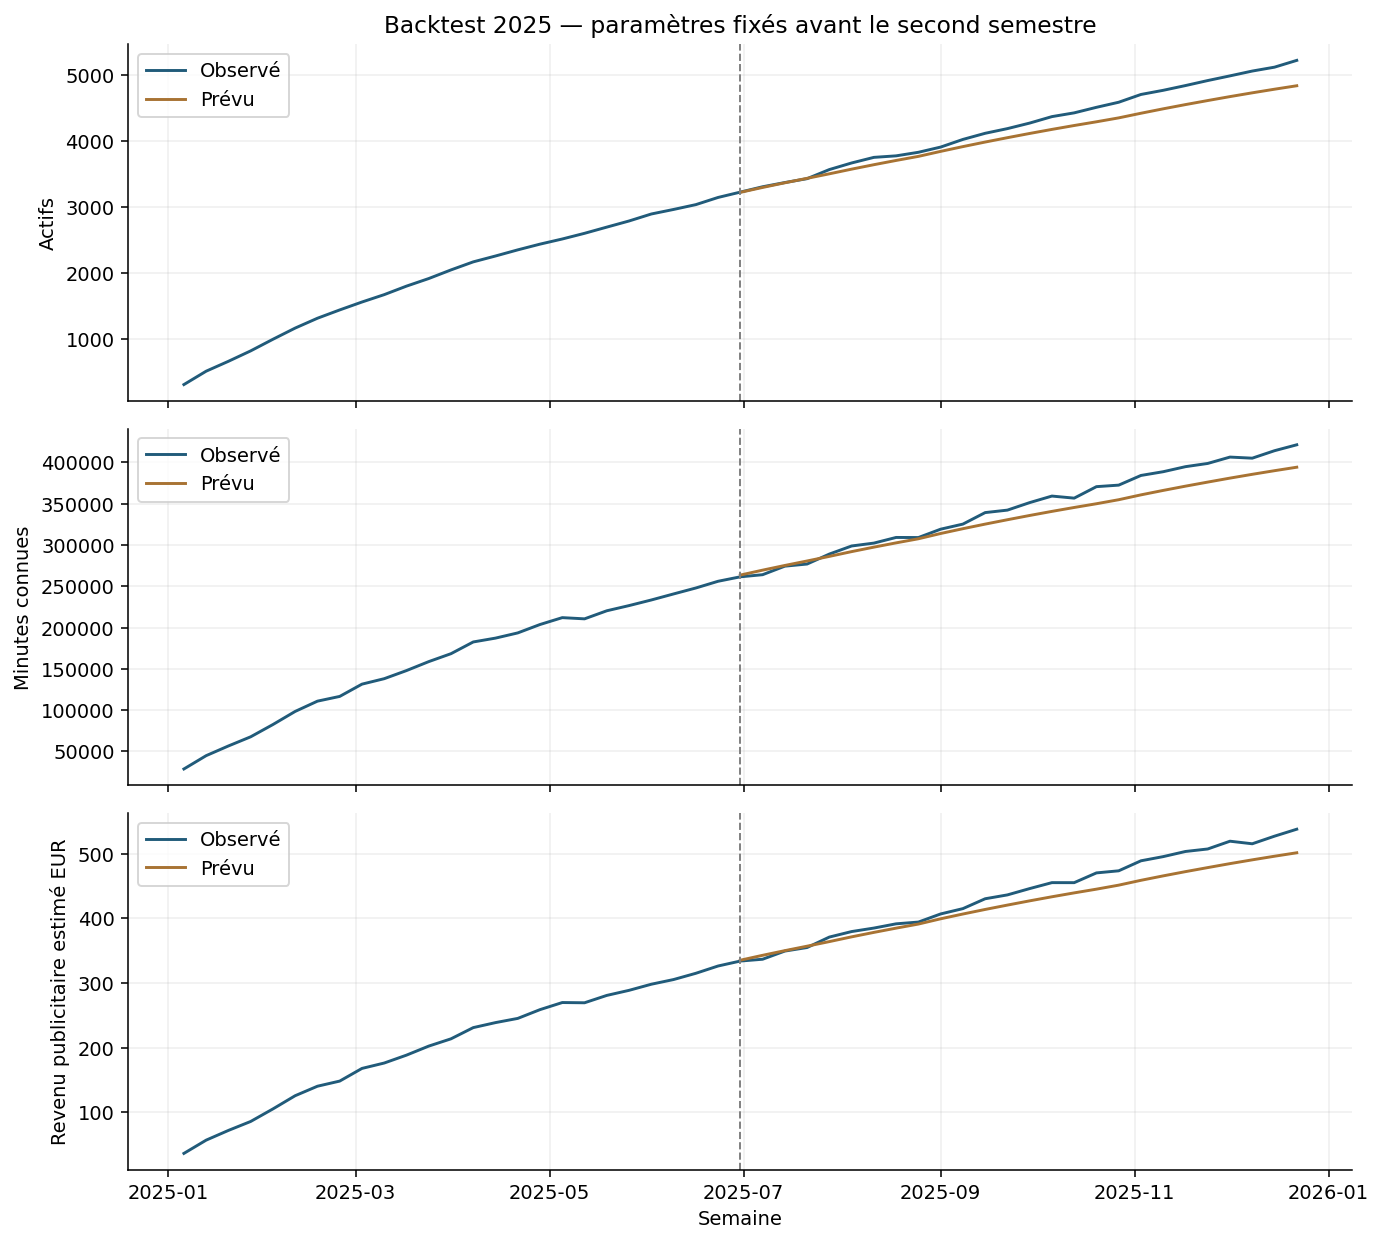

In [28]:
full_2025 = model_activity.loc[model_activity["week_start"].between("2025-01-06", "2025-12-22")].groupby("week_start").agg(
    active=("user_id", "nunique"), minutes=("listening_minutes", "sum"), ads=("ad_impressions", "sum"))
full_2025["revenue"] = full_2025["ads"] * .009
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, metric, label in zip(axes, ["active", "minutes", "revenue"], ["Actifs", "Minutes connues", "Revenu publicitaire estimé EUR"]):
    ax.plot(full_2025.index, full_2025[metric], label="Observé", color="#215b7a")
    ax.plot(backtest.index, backtest[metric], label="Prévu", color="#a87333")
    ax.axvline(backtest.index.min(), color="gray", linestyle="--", linewidth=1)
    ax.set_ylabel(label)
    ax.legend()
axes[0].set_title("Backtest 2025 — paramètres fixés avant le second semestre")
axes[2].set_xlabel("Semaine")
fig.tight_layout()
plt.show()


### Lecture et limites du modèle

- Le modèle simple est retenu sur la validation interne : erreur d'écoute de 1,57 %, contre 2,54 % pour le découpage testé. Cela ne prouve pas que tout modèle par ancienneté est moins bon.
- Sur le test final, l'erreur d'écoute est de 3,85 %, contre 14,27 % pour la tendance linéaire. Les erreurs sur actifs et revenu publicitaire sont proches de 4 %.
- Le biais est négatif : l'écoute cumulée est sous-estimée de 3,58 %. En dernière semaine, le modèle prévoit environ 4 844 actifs contre 5 229 observés. Les paramètres ne sont pas retouchés sur ce test.
- Les maintiens, croissances d'inscriptions et consommations moyennes sont supposés stables. Le taux unique ne reproduit pas toutes les différences d'ancienneté. Le modèle ne prévoit pas de réactivation après une interruption ; aucune n'est observée dans son historique de calibrage.
- Le revenu est publicitaire et brut. Les coûts d'exploitation et ceux des canaux non paid restent inconnus. Une validation sur six mois ne valide pas une LTV à vie : l'extrapolation longue demandera des hypothèses et une sensibilité séparées.

Cette étape fournit le moteur et son backtest. Les budgets et politiques futurs seront fixés dans les trois scénarios de l'étape 7. Aucun effet chiffré paid → organic/podcast n'est présenté comme mesuré.


## Trois scénarios sur vingt six semaines

On conserve les paramètres du modèle validé sur 2025 et on met à jour uniquement le stock actif observé au 28 juin 2026. Les prévisions couvrent les 26 semaines du 29 juin au 27 décembre. La semaine partielle du 29 juin au 5 juillet n'est pas utilisée pour initialiser l'activité.

Les trois scénarios supposent des notifications normales pendant la projection. Ils ne projettent pas directement l'effet du test sur tous les utilisateurs anciens. Les variations de CAC et de départ sont des hypothèses, pas des effets mesurés ni des intervalles de confiance.

Le budget paid reste à 1 630 € par mois. Optimiste : CAC et probabilité de départ réduits de 5 %. Pessimiste : augmentés de 5 %. On modifie les départs, soit 1 − maintien, et non le maintien de cinq points. Les tendances organic/podcast, la consommation et le CPM restent identiques entre scénarios.


In [29]:
from copy import deepcopy

# Paramètres à modifier pour la question du jury, puis relancer les deux cellules suivantes.
BUDGET_PAID_MONTHLY = 1630.0
SCENARIO_CHANGE = 0.05
FORECAST_WEEKS = 26

forecast_cutoff = pd.Timestamp("2026-06-28")
forecast_origin = forecast_cutoff - pd.Timedelta(days=6)
current_state = model_activity.loc[model_activity["week_start"].eq(forecast_origin)].merge(
    model_users[["user_id", "signup_week", "acquisition_channel"]], on="user_id", validate="one_to_one"
).groupby(["signup_week", "acquisition_channel"]).size().rename("active").reset_index()
reference_model = deepcopy(fitted_model)
reference_model["origin"] = forecast_origin
reference_model["state"] = current_state
forecast_end = forecast_origin + pd.Timedelta(weeks=FORECAST_WEEKS, days=6)
future_budgets = pd.Series(BUDGET_PAID_MONTHLY, index=pd.period_range((forecast_origin + pd.Timedelta(weeks=1)).to_period("M"), forecast_end.to_period("M"), freq="M"))
print("Stock initial observé :", int(current_state["active"].sum()), "actifs pendant la semaine du", forecast_origin.date())
print("Projection :", (forecast_origin + pd.Timedelta(weeks=1)).date(), "au", forecast_end.date())
print("Les paramètres de comportement restent ceux du modèle 2025 validé ; ils ne sont pas réestimés sur le groupe agressif.")


Stock initial observé : 7468 actifs pendant la semaine du 2026-06-22
Projection : 2026-06-29 au 2026-12-27
Les paramètres de comportement restent ceux du modèle 2025 validé ; ils ne sont pas réestimés sur le groupe agressif.


In [30]:
scenario_forecasts = {}
scenario_models = {}
scenario_rows = []
for case, change in [("Central", 0.0), ("Optimiste", -SCENARIO_CHANGE), ("Pessimiste", SCENARIO_CHANGE)]:
    case_model = deepcopy(reference_model)
    case_model["cac"] *= 1 + change
    case_model["constant"] = {channel: 1 - (1 - rate) * (1 + change) for channel, rate in reference_model["constant"].items()}
    forecast = predict(case_model, FORECAST_WEEKS, future_budgets, "constant")
    scenario_forecasts[case] = forecast
    scenario_models[case] = case_model
    scenario_rows.append({
        "Scénario": case, "Variation CAC et départs (%)": change * 100,
        "CAC paid EUR": case_model["cac"], "Actifs dernière semaine": forecast["active"].iloc[-1],
        "Minutes cumulées": forecast["minutes"].sum(), "Revenu publicitaire EUR": forecast["revenue"].sum(),
        "Budget paid EUR": forecast["new_paid_social"].sum() * case_model["cac"],
        "Nouveaux inscrits": forecast[[f"new_{c}" for c in CHANNELS]].sum().sum(),
    })
scenario_summary = pd.DataFrame(scenario_rows)
print(scenario_summary.round(2).to_string(index=False))
print("Le budget paid n'est pas l'ensemble des coûts. Le revenu moins ce budget n'est pas un bénéfice net.")
assert all((0 <= rate <= 1) for m in scenario_models.values() for rate in m["constant"].values())
assert scenario_summary["Budget paid EUR"].max() - scenario_summary["Budget paid EUR"].min() < 1e-6
assert scenario_forecasts["Optimiste"]["minutes"].sum() > scenario_forecasts["Central"]["minutes"].sum() > scenario_forecasts["Pessimiste"]["minutes"].sum()


  Scénario  Variation CAC et départs (%)  CAC paid EUR  Actifs dernière semaine  Minutes cumulées  Revenu publicitaire EUR  Budget paid EUR  Nouveaux inscrits
   Central                           0.0          2.61                  8294.03       16492600.78                 20981.51          9678.34           10028.63
 Optimiste                          -5.0          2.48                  8657.96       16968745.04                 21587.48          9678.34           10224.04
Pessimiste                           5.0          2.74                  7956.90       16045439.04                 20412.46          9678.34            9851.82
Le budget paid n'est pas l'ensemble des coûts. Le revenu moins ce budget n'est pas un bénéfice net.


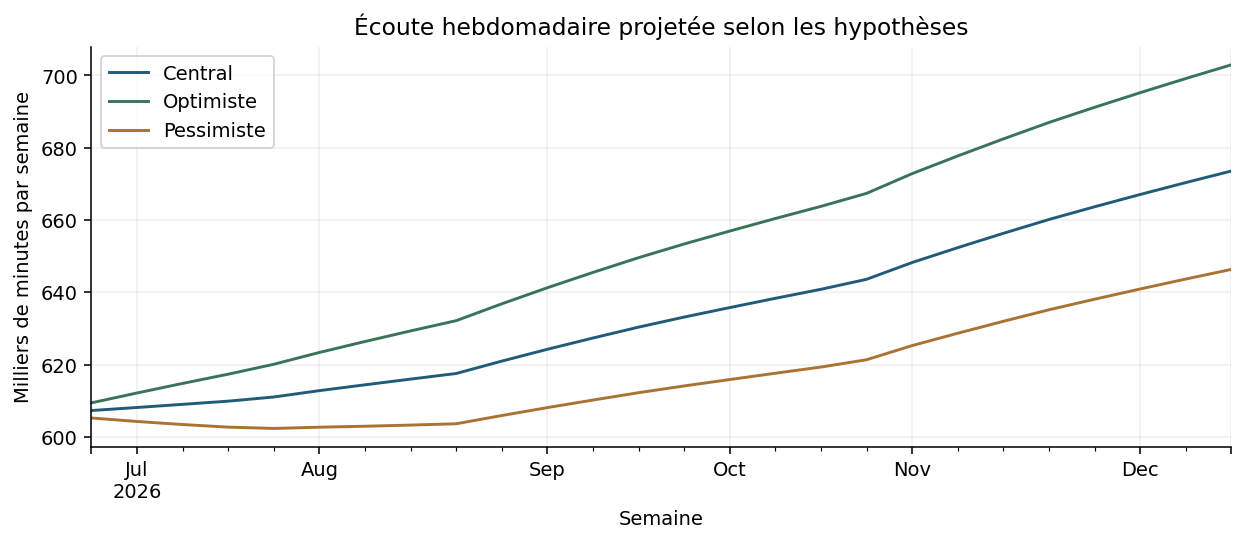

In [31]:
fig, ax = plt.subplots(figsize=(9, 4))
for case, color in [("Central", "#215b7a"), ("Optimiste", "#39745a"), ("Pessimiste", "#a87333")]:
    scenario_forecasts[case]["minutes"].div(1000).plot(ax=ax, label=case, color=color)
ax.set_title("Écoute hebdomadaire projetée selon les hypothèses")
ax.set_ylabel("Milliers de minutes par semaine")
ax.set_xlabel("Semaine")
ax.legend()
fig.tight_layout()
plt.show()


### Valeur publicitaire à horizon observé

Pour approcher la LTV sans inventer une durée de vie, on mesure les revenus publicitaires cumulés sur 12 et 52 semaines pour les mêmes inscrits de janvier à juin 2025. Tous ont ces horizons observables au 28 juin 2026. Les inactifs restent au dénominateur.

Ce sont des revenus bruts à horizon fixe, pas une LTV à vie ni une marge. Le CAC paid est celui des mêmes mois, avec mai estimé. Les coûts des autres canaux sont inconnus. Le payback brut n'est pas atteint en moyenne à 52 semaines pour cette population paid ; il peut être atteint plus tard, sans garantie.


In [32]:
value_users = model_users.loc[model_users["signup_date"].between("2025-01-01", "2025-06-30")].copy()
assert value_users["signup_week"].add(pd.Timedelta(days=51 * 7 + 6)).le(forecast_cutoff).all()
value_activity = model_activity.loc[model_activity["user_id"].isin(value_users["user_id"])].merge(
    value_users[["user_id", "signup_week"]], on="user_id", validate="many_to_one")
value_activity["age"] = value_activity["week_start"].sub(value_activity["signup_week"]).dt.days // 7
for weeks in [12, 52]:
    total = value_activity.loc[value_activity["age"].between(0, weeks - 1)].groupby("user_id")["ad_impressions"].sum() * .009
    value_users[f"revenue_{weeks}w"] = value_users["user_id"].map(total).fillna(0)
value_horizons = value_users.groupby("acquisition_channel").agg(
    users=("user_id", "size"), revenue_12w=("revenue_12w", "mean"), revenue_52w=("revenue_52w", "mean"))
value_horizons["cac_eur"] = np.nan
paid_cost = model_spend.loc[model_spend["month"].between("2025-01-01", "2025-06-01"), "spend_eur"].sum()
value_horizons.loc["paid_social", "cac_eur"] = paid_cost / value_horizons.loc["paid_social", "users"]
print(value_horizons.rename(columns={"users": "Inscrits", "revenue_12w": "Revenu 12 semaines EUR", "revenue_52w": "Revenu 52 semaines EUR", "cac_eur": "CAC EUR"}).round(3).to_string(na_rep="inconnu"))


                     Inscrits  Revenu 12 semaines EUR  Revenu 52 semaines EUR  CAC EUR
acquisition_channel                                                                   
organic_store            1987                   0.991                   2.554  inconnu
paid_social              2456                   0.843                   1.615    2.608
podcast_cross_promo      1018                   1.036                   2.946  inconnu


## Recommandation et prochain test

Nous recommandons de conserver les notifications normales et de ne pas généraliser la version agressive. Le test montre davantage d'ouvertures, mais moins d'écoute et de retours tardifs, sans gain de revenu démontré. Les scénarios macroéconomiques ne remplacent pas cette comparaison randomisée.

Le prochain test proposé compare le fonctionnement normal à une version plafonnée à trois notifications par semaine, avec contenu neutre et réglage utilisateur. Population : nouveaux inscrits ayant autorisé les notifications avant assignation. Randomisation par utilisateur, conservation de tous les assignés, suivi individuel de 84 jours. On instrumente les événements d'écoute pour éviter les limites des agrégats hebdomadaires.

Mesure principale : minutes d'écoute cumulées par assigné. Le dimensionnement vise un effet de 5 %. Garde-fou : rétention en fin de suivi, avec une marge maximale de dégradation de deux points. On suit aussi les désactivations et les plaintes, sans assimiler les ouvertures à de la valeur. Les seuils et la règle de décision seront fixés avant lancement.

Le calcul ci-dessous est un ordre de grandeur avec les données du contrôle : puissance de 80 %, seuil de 5 %, test bilatéral pour l'écoute et unilatéral pour le garde-fou. L'effectif final est le plus exigeant des deux calculs. Les douze semaines sont le suivi de chaque personne, pas la durée totale du recrutement. La part d'inscrits éligibles et les coûts du test restent à mesurer.


In [33]:
from math import ceil
from statistics import NormalDist

normal = NormalDist()
control_outcomes = outcomes.loc[outcomes["push_variant"].eq("control")]
mean_listening = control_outcomes["minutes_known"].mean()
sd_listening = control_outcomes["minutes_known"].std(ddof=1)
retention_reference = control_outcomes["return_s12"].mean()
n_listening = ceil(2 * (normal.inv_cdf(.975) + normal.inv_cdf(.8)) ** 2 * sd_listening ** 2 / (.05 * mean_listening) ** 2)
n_retention = ceil(2 * (normal.inv_cdf(.95) + normal.inv_cdf(.8)) ** 2 * retention_reference * (1 - retention_reference) / .02 ** 2)
planned_per_arm = int(ceil(max(n_listening, n_retention) / 100) * 100)
print("Ordre de grandeur par groupe — écoute :", n_listening, "; garde-fou rétention :", n_retention)
print("Plan proposé :", planned_per_arm, "par groupe, soit", 2 * planned_per_arm, "participants.")
print("Le recrutement peut être long. Ne pas annoncer un résultat global en douze semaines.")
print("Décision proposée : gain d'écoute avec intervalle excluant zéro et garde-fou de rétention respecté ; sinon pas de déploiement. Pas d'arrêt opportuniste sur les résultats intermédiaires.")


Ordre de grandeur par groupe — écoute : 1877 ; garde-fou rétention : 7723
Plan proposé : 7800 par groupe, soit 15600 participants.
Le recrutement peut être long. Ne pas annoncer un résultat global en douze semaines.
Décision proposée : gain d'écoute avec intervalle excluant zéro et garde-fou de rétention respecté ; sinon pas de déploiement. Pas d'arrêt opportuniste sur les résultats intermédiaires.
